
# Práctica 3. Unificación y encadenamiento en lógica de primer orden

**Asignatura:** Inteligencia Artificial (CDC-2411)

**Unidad 3:** Representación del conocimiento y razonamiento

**Subtemas:**

- 3.3. Lógica de primer orden.
- 3.4. Inferencia: unificación y encadenamiento.

**Carrera:** Ingeniería en Ciencia de Datos.

**Modalidad:** Parejas.

## 1. Objetivo

Comprender e implementar el algoritmo de unificación
en lógica de primer orden, aplicando sustituciones
y verificando la ocurrencia de variables.

Desarrollar un algoritmo de encadenamiento hacia
adelante en Python y comparar su funcionamiento
con el encadenamiento hacia atrás realizado mediante
Prolog.

Analizar las diferencias entre ambas estrategias
de inferencia y su relación con los algoritmos
de búsqueda.



## 2. Fundamento teórico

### 2.1. Lógica de primer orden

La lógica de primer orden (LPO) es un sistema
formal que permite representar objetos, propiedades,
relaciones y reglas mediante expresiones lógicas.

A diferencia de la lógica proposicional, la lógica
de primer orden permite utilizar variables,
constantes, predicados, funciones y cuantificadores.

Por ejemplo, en lógica proposicional podemos
representar mediante P la afirmación de que Juan
es estudiante.

En lógica de primer orden podemos expresarla como:

$$Estudiante(Juan)$$

También podemos representar reglas generales:

$$\forall x\ (Estudiante(x)\Rightarrow Persona(x))$$

Esta expresión establece que todo estudiante
es una persona.

La lógica de primer orden permite representar
conocimiento de manera más expresiva y realizar
inferencias sobre diferentes individuos.



### 2.2. Componentes de la lógica de primer orden

| Componente | Descripción | Ejemplo |
|---|---|---|
| Constante | Representa un objeto específico. | Juan, West, Nono |
| Variable | Representa un objeto no especificado. | x, y, z |
| Predicado | Representa una propiedad o relación. | Conoce(x,y) |
| Función | Representa un término determinado por sus argumentos. | Madre(x) |
| Término | Constante, variable o aplicación de una función. | Juan, x, Madre(x) |
| Cuantificador universal | Indica que una expresión se cumple para todos los elementos. | $\forall x$ |
| Cuantificador existencial | Indica que existe al menos un elemento que cumple una expresión. | $\exists x$ |
| Hecho | Afirmación conocida como verdadera. | Americano(West) |
| Regla | Expresión que permite derivar conocimiento. | $P(x)\Rightarrow Q(x)$ |



### 2.3. Unificación

La unificación es el procedimiento mediante el cual
se busca una sustitución que permita hacer idénticas
dos expresiones de lógica de primer orden.

Una sustitución se representa mediante la letra
griega theta:

$$\theta$$

Por ejemplo, consideremos las expresiones:

$$Conoce(Juan,x)$$

$$Conoce(Juan,Juana)$$

Para hacerlas idénticas, se sustituye la variable
x por la constante Juana.

$$\theta=\{x\mapsto Juana\}$$

Al aplicar la sustitución, ambas expresiones
se convierten en:

$$Conoce(Juan,Juana)$$

Por lo tanto, las expresiones son unificables.



### 2.4. Unificador más general (UMG)

El unificador más general es una sustitución
que permite hacer idénticas dos expresiones
imponiendo la menor cantidad posible de
restricciones sobre sus variables.

Por ejemplo:

$$P(x,y)$$

$$P(Juan,z)$$

Un unificador más general es:

$$\theta=\{x\mapsto Juan,\ y\mapsto z\}$$

No es necesario asignar una constante específica
a z, porque ambas expresiones ya coinciden.

El UMG permite conservar la mayor generalidad
posible durante el razonamiento.

En Python representaremos las sustituciones
mediante diccionarios.

Por ejemplo:

    {"x": "Juan", "y": "z"}

Cuando dos expresiones no puedan unificarse,
el algoritmo devolverá None.



### 2.5. Verificación de ocurrencia

La verificación de ocurrencia, conocida como
occurs check, comprueba que una variable no
aparezca dentro del término que se le desea
asignar.

Consideremos:

$$P(x)$$

$$P(F(x))$$

Para unificar ambas expresiones sería necesario
realizar la sustitución:

$$x\mapsto F(x)$$

Sin embargo, la variable x aparece dentro
del término F(x).

Si se aplicara repetidamente esta sustitución,
se produciría una expansión infinita:

$$x=F(x)=F(F(x))=F(F(F(x)))=\cdots$$

Por esta razón, la sustitución no es válida
en la unificación de términos finitos de
lógica de primer orden.

La función ocurre() permitirá detectar este
problema y evitar sustituciones circulares.



### 2.6. Estandarización de variables

La estandarización de variables, también conocida
como renombramiento de variables, consiste en
asignar nombres diferentes a las variables de
distintas reglas.

Por ejemplo:

$$R_1:P(x)\Rightarrow Q(x)$$

$$R_2:Q(x)\Rightarrow R(x)$$

Aunque ambas reglas utilizan la variable x,
cada una posee su propio ámbito.

Para evitar conflictos podemos renombrarlas:

$$R_1:P(x_1)\Rightarrow Q(x_1)$$

$$R_2:Q(x_2)\Rightarrow R(x_2)$$

De esta manera, las sustituciones de una regla
no interfieren con las variables de otra.

La función renombrar() permitirá realizar
esta operación automáticamente.



### 2.7. Encadenamiento hacia adelante

El encadenamiento hacia adelante, o forward
chaining, es una estrategia de inferencia
dirigida por los datos.

El procedimiento comienza con los hechos
conocidos de una base de conocimiento.

Posteriormente, identifica las reglas cuyas
premisas pueden satisfacerse mediante los
hechos disponibles.

Cuando se cumple una regla, su conclusión
se incorpora como un nuevo hecho.

El procedimiento se repite hasta:

- Derivar la meta.
- No obtener nuevos hechos.

Por ejemplo:

Hecho inicial:

$$P(Juan)$$

Reglas:

$$P(x)\Rightarrow Q(x)$$

$$Q(x)\Rightarrow R(x)$$

El encadenamiento permite obtener:

$$P(Juan)\rightarrow Q(Juan)\rightarrow R(Juan)$$

Esta estrategia será implementada en Python
mediante la función fol_fc_ask().



### 2.8. Encadenamiento hacia atrás

El encadenamiento hacia atrás, o backward
chaining, es una estrategia de inferencia
dirigida por objetivos.

El procedimiento comienza con una meta que
se desea demostrar.

Posteriormente, identifica las reglas cuya
conclusión coincide con la meta y convierte
sus premisas en nuevas submetas.

El procedimiento continúa hasta encontrar
hechos que permitan satisfacer las submetas
o hasta que la búsqueda fracase.

Por ejemplo, para demostrar:

$$R(Juan)$$

Se busca una regla que permita obtener R:

$$Q(x)\Rightarrow R(x)$$

La nueva submeta será Q(Juan).

Después se utiliza:

$$P(x)\Rightarrow Q(x)$$

Finalmente, se comprueba que P(Juan) es
un hecho conocido.

Prolog utiliza una estrategia de búsqueda
en profundidad con retroceso para resolver
sus consultas.



### 2.9. Comparación entre estrategias de inferencia

| Característica | Encadenamiento hacia adelante | Encadenamiento hacia atrás |
|---|---|---|
| Punto de partida | Hechos conocidos | Meta |
| Dirección | De los hechos a las conclusiones | De la meta a las premisas |
| Orientación | Datos | Objetivos |
| Funcionamiento | Genera nuevos hechos | Genera submetas |
| Ventaja | Permite descubrir nuevas consecuencias | Se concentra en demostrar una meta |
| Desventaja | Puede generar hechos innecesarios | Puede entrar en ciclos de búsqueda |
| Aplicación en la práctica | Python | Prolog |
| Ejemplo de aplicación | Sistemas de monitoreo | Sistemas de diagnóstico |

Ambas estrategias permiten realizar inferencias
a partir de una base de conocimiento, pero
difieren en la forma de seleccionar y utilizar
las reglas disponibles.



## 3. Caso de estudio: el coronel West

La ley establece que es un crimen que un
estadounidense venda armas a una nación hostil.

El país Nono, enemigo de América, posee misiles.
Todos estos misiles fueron vendidos a Nono por
el coronel West, quien es estadounidense.

A partir de esta información se plantea la
siguiente pregunta:

**¿Es el coronel West un criminal?**

Para responder, representaremos el conocimiento
mediante hechos y reglas de lógica de primer orden.

Posteriormente, utilizaremos dos estrategias
de inferencia:

- Encadenamiento hacia adelante mediante Python.
- Encadenamiento hacia atrás mediante Prolog.

La meta que se desea demostrar es:

$$Criminal(West)$$



### 3.1. Constantes, variables y predicados

#### Constantes

| Constante | Significado |
|---|---|
| West | Coronel estadounidense. |
| Nono | País enemigo de América. |
| America | Nación de referencia. |
| M1 | Misil que posee Nono. |

#### Variables

| Variable | Significado según la regla principal |
|---|---|
| x | Persona que vende un arma. |
| y | Objeto vendido. |
| z | Nación que recibe el arma. |

#### Predicados

| Predicado | Significado | Aridad |
|---|---|---:|
| Americano(x) | x es estadounidense. | 1 |
| Arma(x) | x es un arma. | 1 |
| Misil(x) | x es un misil. | 1 |
| Hostil(x) | x es una nación hostil. | 1 |
| Criminal(x) | x es un criminal. | 1 |
| Posee(x,y) | x posee y. | 2 |
| Enemigo(x,y) | x es enemigo de y. | 2 |
| Vende(x,y,z) | x vende y a z. | 3 |

La aridad indica el número de argumentos
que recibe un predicado.



### 3.2. Hechos de la base de conocimiento

Los hechos representan información conocida
que no necesita ser demostrada.

**H1. Nono posee el misil M1.**

$$Posee(Nono,M1)$$

**H2. M1 es un misil.**

$$Misil(M1)$$

**H3. West es estadounidense.**

$$Americano(West)$$

**H4. Nono es enemigo de América.**

$$Enemigo(Nono,America)$$

Por lo tanto, la base de conocimiento
contiene inicialmente cuatro hechos.



### 3.3. Reglas de inferencia

#### Regla 1. Venta ilegal de armas

Si una persona estadounidense vende un arma
a una nación hostil, entonces es un criminal.

$$\forall x,y,z\ (Americano(x)\land Arma(y)\land Vende(x,y,z)\land Hostil(z)\Rightarrow Criminal(x))$$

#### Regla 2. Venta de misiles

Si un objeto es un misil y Nono lo posee,
entonces West vendió ese misil a Nono.

$$\forall x\ (Misil(x)\land Posee(Nono,x)\Rightarrow Vende(West,x,Nono))$$

#### Regla 3. Clasificación de misiles

Todo misil es un arma.

$$\forall x\ (Misil(x)\Rightarrow Arma(x))$$

#### Regla 4. Naciones hostiles

Toda nación enemiga de América es hostil.

$$\forall x\ (Enemigo(x,America)\Rightarrow Hostil(x))$$

Estas cuatro reglas permiten derivar nuevos
hechos a partir de la información inicial.



### 3.4. Demostración manual mediante encadenamiento hacia adelante

#### Ronda 0. Hechos iniciales

- Posee(Nono,M1)
- Misil(M1)
- Americano(West)
- Enemigo(Nono,America)

#### Ronda 1. Generación de nuevos hechos

Aplicando la regla 2:

$$Misil(M1)\land Posee(Nono,M1)\Rightarrow Vende(West,M1,Nono)$$

Aplicando la regla 3:

$$Misil(M1)\Rightarrow Arma(M1)$$

Aplicando la regla 4:

$$Enemigo(Nono,America)\Rightarrow Hostil(Nono)$$

Se obtienen tres hechos nuevos:

- Vende(West,M1,Nono)
- Arma(M1)
- Hostil(Nono)

#### Ronda 2. Demostración de la meta

Aplicando la regla 1 con la sustitución:

$$\theta=\{x\mapsto West,\ y\mapsto M1,\ z\mapsto Nono\}$$

Se satisfacen las cuatro premisas:

- Americano(West)
- Arma(M1)
- Vende(West,M1,Nono)
- Hostil(Nono)

Por lo tanto:

$$\therefore Criminal(West)$$

La meta se demuestra en la segunda ronda
del encadenamiento hacia adelante.



### 3.5. Resumen del encadenamiento

| Ronda | Regla aplicada | Hecho nuevo |
|---:|---|---|
| 0 | Ninguna | Cuatro hechos iniciales |
| 1 | R2 | Vende(West,M1,Nono) |
| 1 | R3 | Arma(M1) |
| 1 | R4 | Hostil(Nono) |
| 2 | R1 | Criminal(West) |

#### Resultados esperados

| Indicador | Cantidad |
|---|---:|
| Hechos iniciales | 4 |
| Reglas disponibles | 4 |
| Hechos nuevos en la primera ronda | 3 |
| Hechos nuevos en la segunda ronda | 1 |
| Total de hechos derivados | 4 |
| Total de hechos finales | 8 |
| Rondas necesarias para alcanzar la meta | 2 |

La demostración permite concluir que
Criminal(West) es una consecuencia lógica
de la base de conocimiento.



## 4. Preguntas previas

### Pregunta 1

**Escribe en lógica de primer orden las cuatro
reglas del caso West.**

**Respuesta:**

Regla 1:

$$\forall x,y,z\ (Americano(x)\land Arma(y)\land Vende(x,y,z)\land Hostil(z)\Rightarrow Criminal(x))$$

Regla 2:

$$\forall x\ (Misil(x)\land Posee(Nono,x)\Rightarrow Vende(West,x,Nono))$$

Regla 3:

$$\forall x\ (Misil(x)\Rightarrow Arma(x))$$

Regla 4:

$$\forall x\ (Enemigo(x,America)\Rightarrow Hostil(x))$$

Las reglas establecen las condiciones necesarias
para derivar nuevos hechos y demostrar que West
es un criminal.



### Pregunta 2

**¿Cuál es el UMG de Conoce(Juan,x)
y Conoce(y,Isabel)?**

**Respuesta:**

Consideremos las expresiones:

$$Conoce(Juan,x)$$

$$Conoce(y,Isabel)$$

Primero se comparan los nombres de los
predicados, los cuales coinciden.

Después se comparan sus argumentos.

Primer argumento:

$$Juan=y$$

Por lo tanto:

$$y\mapsto Juan$$

Segundo argumento:

$$x=Isabel$$

Por lo tanto:

$$x\mapsto Isabel$$

El unificador más general es:

$$\boxed{\theta=\{y\mapsto Juan,\ x\mapsto Isabel\}}$$

Al aplicar la sustitución, ambas expresiones
se convierten en:

$$Conoce(Juan,Isabel)$$

En Python, el resultado se representará como:

    {"y": "Juan", "x": "Isabel"}



### Pregunta 3

**¿Por qué P(x) y P(F(x)) no unifican?**

**Respuesta:**

Para unificar las expresiones:

$$P(x)$$

$$P(F(x))$$

Sería necesario realizar la sustitución:

$$x\mapsto F(x)$$

Sin embargo, la variable x aparece dentro
del término F(x).

Esto produciría una sustitución circular:

$$x=F(x)=F(F(x))=F(F(F(x)))=\cdots$$

La verificación de ocurrencia detecta que
la variable está contenida dentro del término
que se le pretende asignar.

Por lo tanto, no existe un unificador válido
para estas expresiones utilizando términos
finitos de lógica de primer orden.

El algoritmo de unificación deberá devolver:

    None



## 5. Parte A. Implementación en Python

### 5.1. Representación de términos y expresiones

Para implementar la lógica de primer orden
en Python utilizaremos cadenas de texto,
tuplas y diccionarios.

Las convenciones establecidas serán:

- Variables: cadenas que comienzan con minúscula.
- Constantes: cadenas que comienzan con mayúscula.
- Expresiones compuestas: tuplas.
- Sustituciones: diccionarios.
- Hechos: conjuntos de tuplas.
- Reglas: pares de premisas y conclusión.

| Elemento | Lógica de primer orden | Python |
|---|---|---|
| Variable | x | `"x"` |
| Constante | Juan | `"Juan"` |
| Predicado | Conoce(Juan,x) | `("Conoce","Juan","x")` |
| Función | Madre(x) | `("Madre","x")` |
| Sustitución | x → Juan | `{"x":"Juan"}` |
| Hecho | Misil(M1) | `("Misil","M1")` |

Las tuplas permiten representar expresiones
compuestas, incluyendo funciones anidadas.

Los diccionarios permiten asociar cada variable
con el término que la sustituye.


In [1]:

# Biblioteca para generar combinaciones de hechos
import itertools

# Biblioteca para organizar los resultados en tablas
import pandas as pd

# Biblioteca para generar gráficas
import matplotlib.pyplot as plt


In [2]:

# Ejemplos de representación de términos

variable = "x"

constante = "Juan"

predicado = ("Conoce", "Juan", "x")

funcion = ("Madre", "x")

expresion_compuesta = ("Conoce", "Juan", ("Madre", "x"))

sustitucion = {"x": "Juan"}

# Mostrar los elementos
print("Variable:", variable)
print("Constante:", constante)
print("Predicado:", predicado)
print("Función:", funcion)
print("Expresión compuesta:", expresion_compuesta)
print("Sustitución:", sustitucion)


Variable: x
Constante: Juan
Predicado: ('Conoce', 'Juan', 'x')
Función: ('Madre', 'x')
Expresión compuesta: ('Conoce', 'Juan', ('Madre', 'x'))
Sustitución: {'x': 'Juan'}



### 5.2. Función es_var()

La función es_var() determina si un término
representa una variable.

De acuerdo con las convenciones establecidas,
una variable debe ser una cadena de texto
que comienza con una letra minúscula.

Por ejemplo:

- x es una variable.
- y es una variable.
- x1 es una variable.
- Juan no es una variable.
- West no es una variable.
- Madre(x) no es una variable.

La función devuelve:

- True: si el término es una variable.
- False: si el término no es una variable.


In [3]:

def es_var(t):
    """
    Determina si un término representa una variable.

    Parámetro:
        t: término que se desea evaluar.

    Retorna:
        True si es una variable.
        False en caso contrario.
    """

    return isinstance(t, str) and bool(t) and t[0].islower()


In [4]:

# Pruebas de la función es_var()

terminos = [
    "x",
    "y",
    "x1",
    "Juan",
    "West",
    "M1",
    ("Madre", "x"),
    25,
    ""
]

for termino in terminos:
    print(f"{str(termino):20} -> {es_var(termino)}")


x                    -> True
y                    -> True
x1                   -> True
Juan                 -> False
West                 -> False
M1                   -> False
('Madre', 'x')       -> False
25                   -> False
                     -> False



### 5.3. Función sustituir()

La función sustituir() aplica un conjunto de
sustituciones a un término.

Consideremos la expresión:

$$Conoce(x,y)$$

Y la sustitución:

$$\theta=\{x\mapsto Juan,\ y\mapsto Isabel\}$$

Al aplicar la sustitución se obtiene:

$$Conoce(Juan,Isabel)$$

La función debe considerar tres casos:

1. Si el término es una variable, buscar su
   sustitución en el diccionario.

2. Si el término es una tupla, aplicar la
   sustitución recursivamente a sus elementos.

3. Si el término es una constante, devolverlo
   sin modificaciones.

La recursividad permite resolver sustituciones
encadenadas y expresiones anidadas.


In [5]:

def sustituir(t, s):
    """
    Aplica una sustitución a un término.

    Parámetros:
        t: término original.
        s: diccionario de sustituciones.

    Retorna:
        El término después de aplicar las sustituciones.
    """

    # Caso 1: el término es una variable
    if es_var(t):

        # Si existe una sustitución, aplicarla recursivamente
        if t in s:
            return sustituir(s[t], s)

        # Si no existe, conservar la variable
        return t

    # Caso 2: el término es una expresión compuesta
    if isinstance(t, tuple):

        # Aplicar las sustituciones a cada elemento
        return tuple(sustituir(a, s) for a in t)

    # Caso 3: el término es una constante
    return t


In [6]:

# Prueba 1: sustitución de una variable
print("Prueba 1:")
print(sustituir("x", {"x": "Juan"}))

# Prueba 2: sustitución de una expresión
print("\nPrueba 2:")
print(sustituir(
    ("Conoce", "x", "y"),
    {"x": "Juan", "y": "Isabel"}
))

# Prueba 3: sustituciones encadenadas
print("\nPrueba 3:")
print(sustituir(
    "x",
    {"x": "y", "y": "Juan"}
))

# Prueba 4: expresión anidada
print("\nPrueba 4:")
print(sustituir(
    ("Conoce", "Juan", ("Madre", "x")),
    {"x": "Isabel"}
))

# Prueba 5: variable sin sustitución
print("\nPrueba 5:")
print(sustituir("z", {"x": "Juan"}))

# Prueba 6: constante
print("\nPrueba 6:")
print(sustituir("West", {"x": "Juan"}))


Prueba 1:
Juan

Prueba 2:
('Conoce', 'Juan', 'Isabel')

Prueba 3:
Juan

Prueba 4:
('Conoce', 'Juan', ('Madre', 'Isabel'))

Prueba 5:
z

Prueba 6:
West



### 5.4. Función ocurre()

La función ocurre() implementa la verificación
de ocurrencia (occurs check).

Su objetivo es determinar si una variable
aparece dentro de un término.

Por ejemplo:

| Variable | Término | ¿Ocurre? |
|---|---|---|
| x | Juan | No |
| x | x | Sí |
| x | F(x) | Sí |
| x | F(y) | No |
| x | F(G(x)) | Sí |

Antes de realizar la comprobación se aplican
las sustituciones existentes.

Esto permite detectar ocurrencias indirectas.

Por ejemplo, si:

$$\theta=\{y\mapsto x\}$$

Entonces el término F(y) se transforma en F(x).

Por lo tanto, x ocurre indirectamente
dentro de F(y).

La función devuelve True si la variable
aparece dentro del término y False en
caso contrario.


In [7]:

def ocurre(v, t, s):
    """
    Comprueba si una variable aparece dentro de un término.

    Parámetros:
        v: variable que se desea buscar.
        t: término que se desea evaluar.
        s: diccionario de sustituciones existentes.

    Retorna:
        True si la variable aparece dentro del término.
        False en caso contrario.
    """

    # Aplicar las sustituciones existentes
    t = sustituir(t, s)

    # Caso 1: la variable coincide con el término
    if v == t:
        return True

    # Caso 2: el término es una expresión compuesta
    if isinstance(t, tuple):

        # Buscar la variable dentro de sus argumentos
        return any(ocurre(v, a, s) for a in t[1:])

    # Caso 3: la variable no aparece
    return False


In [8]:

# Pruebas de la función ocurre()

pruebas_ocurre = [
    ("x", "Juan", {}),
    ("x", "x", {}),
    ("x", ("F", "x"), {}),
    ("x", ("F", "y"), {}),
    ("x", ("F", ("G", "x")), {}),
    ("x", ("F", ("G", "y")), {}),
    ("x", ("F", "y"), {"y": "x"}),
    ("x", ("F", "y"), {"y": "Juan"})
]

for i, (v, t, s) in enumerate(pruebas_ocurre, start=1):

    resultado = ocurre(v, t, s)

    print(f"Prueba {i}:")
    print(f"  Variable: {v}")
    print(f"  Término: {t}")
    print(f"  Sustituciones: {s}")
    print(f"  Resultado: {resultado}")
    print("-" * 45)


Prueba 1:
  Variable: x
  Término: Juan
  Sustituciones: {}
  Resultado: False
---------------------------------------------
Prueba 2:
  Variable: x
  Término: x
  Sustituciones: {}
  Resultado: True
---------------------------------------------
Prueba 3:
  Variable: x
  Término: ('F', 'x')
  Sustituciones: {}
  Resultado: True
---------------------------------------------
Prueba 4:
  Variable: x
  Término: ('F', 'y')
  Sustituciones: {}
  Resultado: False
---------------------------------------------
Prueba 5:
  Variable: x
  Término: ('F', ('G', 'x'))
  Sustituciones: {}
  Resultado: True
---------------------------------------------
Prueba 6:
  Variable: x
  Término: ('F', ('G', 'y'))
  Sustituciones: {}
  Resultado: False
---------------------------------------------
Prueba 7:
  Variable: x
  Término: ('F', 'y')
  Sustituciones: {'y': 'x'}
  Resultado: True
---------------------------------------------
Prueba 8:
  Variable: x
  Término: ('F', 'y')
  Sustituciones: {'y': 'Juan'}
  R

In [9]:

# Almacenar los resultados de las pruebas

resultados_ocurre = []

for i, (v, t, s) in enumerate(pruebas_ocurre, start=1):

    resultados_ocurre.append({
        "Prueba": i,
        "Variable": v,
        "Término": str(t),
        "Sustituciones": str(s),
        "Resultado": ocurre(v, t, s)
    })

# Crear DataFrame
df_ocurre = pd.DataFrame(resultados_ocurre)

# Mostrar tabla
df_ocurre


,Prueba,Variable,Término,Sustituciones,Resultado
0,1,x,Juan,{},False
1,2,x,x,{},True
2,3,x,"('F', 'x')",{},True
3,4,x,"('F', 'y')",{},False
4,5,x,"('F', ('G', 'x'))",{},True
5,6,x,"('F', ('G', 'y'))",{},False
6,7,x,"('F', 'y')",{'y': 'x'},True
7,8,x,"('F', 'y')",{'y': 'Juan'},False


In [10]:

# Verificación de es_var()

assert es_var("x") is True
assert es_var("x1") is True
assert es_var("Juan") is False
assert es_var(("F", "x")) is False
assert es_var("") is False

# Verificación de sustituir()

assert sustituir("x", {"x": "Juan"}) == "Juan"

assert sustituir(
    "x", {"x": "y", "y": "Juan"}
) == "Juan"

assert sustituir(
    ("P", "x"), {"x": "Juan"}
) == ("P", "Juan")

# Verificación de ocurre()

assert ocurre("x", "Juan", {}) is False
assert ocurre("x", "x", {}) is True
assert ocurre("x", ("F", "x"), {}) is True
assert ocurre("x", ("F", "y"), {}) is False
assert ocurre("x", ("F", ("G", "x")), {}) is True
assert ocurre("x", ("F", "y"), {"y": "x"}) is True

print("Todas las pruebas se ejecutaron correctamente.")
print("Las tres funciones auxiliares están verificadas.")


Todas las pruebas se ejecutaron correctamente.
Las tres funciones auxiliares están verificadas.



### 5.5. Análisis de las funciones auxiliares

Las tres funciones implementadas constituyen
la base del algoritmo de unificación.

| Función | Responsabilidad |
|---|---|
| es_var() | Identificar variables. |
| sustituir() | Aplicar sustituciones. |
| ocurre() | Detectar ocurrencias directas e indirectas. |

La función es_var() permite distinguir
variables de constantes.

La función sustituir() permite aplicar
sustituciones simples, encadenadas y anidadas.

La función ocurre() permite detectar
sustituciones circulares antes de incorporarlas
al diccionario de sustituciones.

Estas funciones serán utilizadas por el
algoritmo unificar() para calcular el
unificador más general de dos expresiones.



### 5.6. Función unificar()

La función unificar() busca una sustitución que
permita hacer idénticos dos términos o expresiones
de lógica de primer orden.

El algoritmo considera los siguientes casos:

1. Si las expresiones son iguales, devuelve las
   sustituciones existentes.

2. Si la primera expresión es una variable,
   intenta asignarle la segunda expresión.

3. Si la segunda expresión es una variable,
   intenta asignarle la primera expresión.

4. Si ambas expresiones son tuplas, verifica
   que tengan el mismo nombre y número de
   argumentos, y unifica sus argumentos.

5. Si ninguna condición anterior se cumple,
   las expresiones no son unificables.

Antes de asignar un término a una variable,
se realiza la verificación de ocurrencia
para evitar sustituciones circulares.

La función devuelve un diccionario con el
unificador más general o None cuando la
unificación no es posible.


In [11]:

def unificar(x, y, s=None):
    """
    Calcula el unificador más general de dos términos.

    Parámetros:
        x: primer término.
        y: segundo término.
        s: diccionario de sustituciones existentes.

    Retorna:
        Diccionario con las sustituciones del UMG.
        None si los términos no pueden unificarse.
    """

    # Inicializar el diccionario de sustituciones
    if s is None:
        s = {}
    else:
        s = s.copy()

    # Aplicar las sustituciones existentes
    x = sustituir(x, s)
    y = sustituir(y, s)

    # Caso 1: los términos son iguales
    if x == y:
        return s

    # Caso 2: x es una variable
    if es_var(x):

        # Verificar que x no aparezca dentro de y
        if ocurre(x, y, s):
            return None

        # Agregar la sustitución
        s[x] = y
        return s

    # Caso 3: y es una variable
    if es_var(y):

        # Verificar que y no aparezca dentro de x
        if ocurre(y, x, s):
            return None

        # Agregar la sustitución
        s[y] = x
        return s

    # Caso 4: ambos términos son expresiones compuestas
    if isinstance(x, tuple) and isinstance(y, tuple):

        # Verificar que tengan la misma longitud
        if len(x) != len(y):
            return None

        # Verificar que tengan el mismo nombre
        if x[0] != y[0]:
            return None

        # Unificar los argumentos uno por uno
        for a, b in zip(x[1:], y[1:]):

            s = unificar(a, b, s)

            # Si algún argumento no unifica,
            # toda la expresión falla
            if s is None:
                return None

        return s

    # Caso 5: términos incompatibles
    return None


In [12]:

# Pruebas básicas de unificar()

pruebas_basicas = [
    ("Juan", "Juan"),
    ("Juan", "Isabel"),
    ("x", "Juan"),
    ("Juan", "y"),
    ("x", "y"),
    (("P", "x"), ("P", "Juan")),
    (("P", "x"), ("Q", "Juan")),
    (("P", "x"), ("P", "Juan", "Isabel")),
    (("P", "x"), ("P", ("F", "x")))
]

for i, (a, b) in enumerate(pruebas_basicas, start=1):

    resultado = unificar(a, b)

    print(f"Prueba {i}:")
    print(f"  Expresión 1: {a}")
    print(f"  Expresión 2: {b}")
    print(f"  UMG: {resultado}")
    print("-" * 45)


Prueba 1:
  Expresión 1: Juan
  Expresión 2: Juan
  UMG: {}
---------------------------------------------
Prueba 2:
  Expresión 1: Juan
  Expresión 2: Isabel
  UMG: None
---------------------------------------------
Prueba 3:
  Expresión 1: x
  Expresión 2: Juan
  UMG: {'x': 'Juan'}
---------------------------------------------
Prueba 4:
  Expresión 1: Juan
  Expresión 2: y
  UMG: {'y': 'Juan'}
---------------------------------------------
Prueba 5:
  Expresión 1: x
  Expresión 2: y
  UMG: {'x': 'y'}
---------------------------------------------
Prueba 6:
  Expresión 1: ('P', 'x')
  Expresión 2: ('P', 'Juan')
  UMG: {'x': 'Juan'}
---------------------------------------------
Prueba 7:
  Expresión 1: ('P', 'x')
  Expresión 2: ('Q', 'Juan')
  UMG: None
---------------------------------------------
Prueba 8:
  Expresión 1: ('P', 'x')
  Expresión 2: ('P', 'Juan', 'Isabel')
  UMG: None
---------------------------------------------
Prueba 9:
  Expresión 1: ('P', 'x')
  Expresión 2: ('P', ('F


### 5.7. Ejercicios de unificación

Se evaluarán los cinco pares de expresiones
establecidos en el manual de prácticas.

| Prueba | Expresión 1 | Expresión 2 |
|---|---|---|
| 1 | Conoce(Juan,x) | Conoce(Juan,Juana) |
| 2 | Conoce(Juan,x) | Conoce(y,Isabel) |
| 3 | Conoce(Juan,x) | Conoce(y,Madre(y)) |
| 4 | Conoce(Juan,x) | Conoce(x,Isabel) |
| 5 | P(x) | P(F(x)) |

El algoritmo deberá determinar el unificador
más general de cada par.

De acuerdo con los puntos de verificación
del manual, tres pares deben unificarse
correctamente y dos deben devolver None.


In [13]:

# Cinco ejercicios establecidos en el manual

pruebas = [
    (
        ("Conoce", "Juan", "x"),
        ("Conoce", "Juan", "Juana")
    ),
    (
        ("Conoce", "Juan", "x"),
        ("Conoce", "y", "Isabel")
    ),
    (
        ("Conoce", "Juan", "x"),
        ("Conoce", "y", ("Madre", "y"))
    ),
    (
        ("Conoce", "Juan", "x"),
        ("Conoce", "x", "Isabel")
    ),
    (
        ("P", "x"),
        ("P", ("F", "x"))
    )
]

# Ejecutar las cinco pruebas
for i, (a, b) in enumerate(pruebas, start=1):

    print(f"PRUEBA {i}")
    print(f"Expresión 1: {a}")
    print(f"Expresión 2: {b}")
    print(f"UMG: {unificar(a, b)}")
    print("=" * 60)


PRUEBA 1
Expresión 1: ('Conoce', 'Juan', 'x')
Expresión 2: ('Conoce', 'Juan', 'Juana')
UMG: {'x': 'Juana'}
PRUEBA 2
Expresión 1: ('Conoce', 'Juan', 'x')
Expresión 2: ('Conoce', 'y', 'Isabel')
UMG: {'y': 'Juan', 'x': 'Isabel'}
PRUEBA 3
Expresión 1: ('Conoce', 'Juan', 'x')
Expresión 2: ('Conoce', 'y', ('Madre', 'y'))
UMG: {'y': 'Juan', 'x': ('Madre', 'Juan')}
PRUEBA 4
Expresión 1: ('Conoce', 'Juan', 'x')
Expresión 2: ('Conoce', 'x', 'Isabel')
UMG: None
PRUEBA 5
Expresión 1: ('P', 'x')
Expresión 2: ('P', ('F', 'x'))
UMG: None



### 5.8. Análisis de la prueba 1

Expresiones:

$$Conoce(Juan,x)$$

$$Conoce(Juan,Juana)$$

El nombre del predicado coincide.

El primer argumento es igual en ambas expresiones.

El segundo argumento requiere la sustitución:

$$x\mapsto Juana$$

Por lo tanto, el UMG es:

$$\theta=\{x\mapsto Juana\}$$

Al aplicar la sustitución se obtiene:

$$Conoce(Juan,Juana)$$

**Resultado:** las expresiones son unificables.



### 5.9. Análisis de la prueba 2

Expresiones:

$$Conoce(Juan,x)$$

$$Conoce(y,Isabel)$$

Se comparan los primeros argumentos:

$$Juan=y$$

Se obtiene la sustitución:

$$y\mapsto Juan$$

Posteriormente, se comparan los segundos argumentos:

$$x=Isabel$$

Se obtiene:

$$x\mapsto Isabel$$

El UMG es:

$$\theta=\{y\mapsto Juan,\ x\mapsto Isabel\}$$

La expresión resultante es:

$$Conoce(Juan,Isabel)$$

**Resultado:** las expresiones son unificables.



### 5.10. Análisis de la prueba 3

Expresiones:

$$Conoce(Juan,x)$$

$$Conoce(y,Madre(y))$$

Primero se comparan los primeros argumentos:

$$Juan=y$$

Se obtiene:

$$y\mapsto Juan$$

Después se comparan los segundos argumentos:

$$x=Madre(y)$$

Aplicando la sustitución anterior:

$$x=Madre(Juan)$$

Por lo tanto:

$$x\mapsto Madre(Juan)$$

El UMG es:

$$\theta=\{y\mapsto Juan,\ x\mapsto Madre(Juan)\}$$

La expresión resultante es:

$$Conoce(Juan,Madre(Juan))$$

**Resultado:** las expresiones son unificables.

Esta prueba demuestra que el algoritmo puede
procesar funciones anidadas y aplicar las
sustituciones obtenidas anteriormente.



### 5.11. Análisis de la prueba 4

Expresiones:

$$Conoce(Juan,x)$$

$$Conoce(x,Isabel)$$

Al comparar los primeros argumentos:

$$Juan=x$$

Se obtiene:

$$x\mapsto Juan$$

Al comparar los segundos argumentos:

$$x=Isabel$$

Sin embargo, la variable x ya fue sustituida
por Juan.

Por lo tanto, sería necesario que:

$$Juan=Isabel$$

Como Juan e Isabel son constantes distintas,
la unificación falla.

**Resultado:** None.

La causa del fallo es la incompatibilidad
entre constantes.



### 5.12. Análisis de la prueba 5

Expresiones:

$$P(x)$$

$$P(F(x))$$

Para unificar ambas expresiones sería necesario:

$$x\mapsto F(x)$$

Sin embargo, la variable x aparece dentro
del término F(x).

La función ocurre() detecta esta situación
y evita que se genere una sustitución circular.

Por lo tanto, no existe un unificador válido
para estas expresiones con términos finitos.

**Resultado:** None.

La causa del fallo es la verificación
de ocurrencia.



### 5.13. Formato de las expresiones lógicas

Para facilitar la interpretación de los
resultados, se implementará una función
auxiliar que transforme las tuplas de Python
en expresiones de lógica de primer orden.

Por ejemplo:

    ("Conoce", "Juan", "x")

Se mostrará como:

    Conoce(Juan, x)

Esta función únicamente modifica la forma
en que se presentan los términos, sin alterar
el funcionamiento del algoritmo de unificación.


In [14]:

def formato_termino(t):
    """
    Convierte un término de Python en una
    expresión de lógica de primer orden.
    """

    # Si es una expresión compuesta
    if isinstance(t, tuple):

        nombre = t[0]

        argumentos = ", ".join(
            formato_termino(a) for a in t[1:]
        )

        return f"{nombre}({argumentos})"

    # Si es una variable o constante
    return str(t)


def formato_sustitucion(s):
    """
    Convierte un diccionario de sustituciones
    en una representación legible.
    """

    # Si la unificación falló
    if s is None:
        return "None"

    elementos = [
        f"{v} → {formato_termino(t)}"
        for v, t in s.items()
    ]

    return "{" + ", ".join(elementos) + "}"


In [15]:

# Probar las funciones de formato

print(formato_termino(
    ("Conoce", "Juan", ("Madre", "Juan"))
))

print(formato_sustitucion({
    "y": "Juan",
    "x": ("Madre", "Juan")
}))


Conoce(Juan, Madre(Juan))
{y → Juan, x → Madre(Juan)}


In [16]:

resultados_unificacion = []

for i, (a, b) in enumerate(pruebas, start=1):

    # Obtener el unificador
    umg = unificar(a, b)

    # Determinar si la unificación fue exitosa
    exito = umg is not None

    # Obtener la expresión resultante
    if exito:
        expresion_final = formato_termino(
            sustituir(a, umg)
        )
    else:
        expresion_final = "No aplica"

    # Almacenar los resultados
    resultados_unificacion.append({
        "Prueba": i,
        "Expresión 1": formato_termino(a),
        "Expresión 2": formato_termino(b),
        "UMG": formato_sustitucion(umg),
        "Unificable": exito,
        "Expresión resultante": expresion_final
    })

# Crear DataFrame
df_unificacion = pd.DataFrame(resultados_unificacion)

# Mostrar los resultados
df_unificacion


,Prueba,Expresión 1,Expresión 2,UMG,Unificable,Expresión resultante
0,1,"Conoce(Juan, x)","Conoce(Juan, Juana)",{x → Juana},True,"Conoce(Juan, Juana)"
1,2,"Conoce(Juan, x)","Conoce(y, Isabel)","{y → Juan, x → Isabel}",True,"Conoce(Juan, Isabel)"
2,3,"Conoce(Juan, x)","Conoce(y, Madre(y))","{y → Juan, x → Madre(Juan)}",True,"Conoce(Juan, Madre(Juan))"
3,4,"Conoce(Juan, x)","Conoce(x, Isabel)",None,False,No aplica
4,5,P(x),P(F(x)),None,False,No aplica


In [17]:

# Verificación de los cinco ejercicios

resultados_esperados = [
    {"x": "Juana"},
    {"y": "Juan", "x": "Isabel"},
    {"y": "Juan", "x": ("Madre", "Juan")},
    None,
    None
]

for i, (a, b) in enumerate(pruebas):

    umg = unificar(a, b)

    # Comprobar el resultado esperado
    assert umg == resultados_esperados[i]

    # Si existe un UMG, verificar ambas expresiones
    if umg is not None:

        expresion_a = sustituir(a, umg)
        expresion_b = sustituir(b, umg)

        assert expresion_a == expresion_b

    print(f"Prueba {i + 1}: CORRECTA")

print("\nLos cinco ejercicios fueron verificados.")


Prueba 1: CORRECTA
Prueba 2: CORRECTA
Prueba 3: CORRECTA
Prueba 4: CORRECTA
Prueba 5: CORRECTA

Los cinco ejercicios fueron verificados.


In [18]:

# Calcular estadísticas de unificación

total_pruebas = len(df_unificacion)

exitosas = int(df_unificacion["Unificable"].sum())

fallidas = total_pruebas - exitosas

porcentaje_exitosas = exitosas / total_pruebas * 100

porcentaje_fallidas = fallidas / total_pruebas * 100

# Mostrar estadísticas
print("ESTADÍSTICAS DE UNIFICACIÓN")
print("-" * 40)

print(f"Total de pruebas: {total_pruebas}")
print(f"Expresiones unificables: {exitosas}")
print(f"Expresiones no unificables: {fallidas}")

print(f"Porcentaje unificables: {porcentaje_exitosas:.2f}%")
print(f"Porcentaje no unificables: {porcentaje_fallidas:.2f}%")


ESTADÍSTICAS DE UNIFICACIÓN
----------------------------------------
Total de pruebas: 5
Expresiones unificables: 3
Expresiones no unificables: 2
Porcentaje unificables: 60.00%
Porcentaje no unificables: 40.00%



### 5.14. Visualización de los resultados

Se generarán gráficas para representar la
cantidad y proporción de expresiones
unificables y no unificables.

Estas visualizaciones permitirán comprobar
los resultados establecidos en el manual
y analizar el comportamiento del algoritmo.


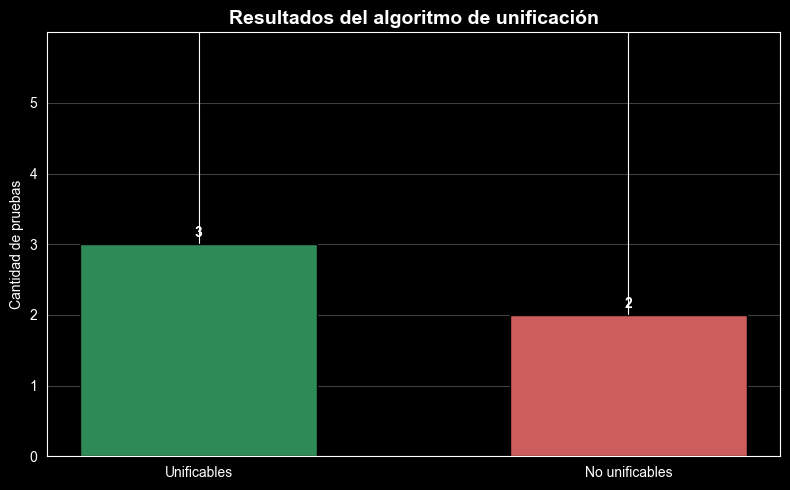

In [19]:

categorias = [
    "Unificables",
    "No unificables"
]

cantidades = [
    exitosas,
    fallidas
]

plt.figure(figsize=(8, 5))

barras = plt.bar(
    categorias,
    cantidades,
    color=["seagreen", "indianred"],
    edgecolor="black",
    width=0.55
)

plt.title(
    "Resultados del algoritmo de unificación",
    fontsize=14,
    fontweight="bold"
)

plt.ylabel("Cantidad de pruebas")
plt.ylim(0, total_pruebas + 1)
plt.yticks(range(total_pruebas + 1))

for barra, cantidad in zip(barras, cantidades):

    plt.text(
        barra.get_x() + barra.get_width() / 2,
        cantidad + 0.1,
        str(cantidad),
        ha="center",
        fontweight="bold"
    )

plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()


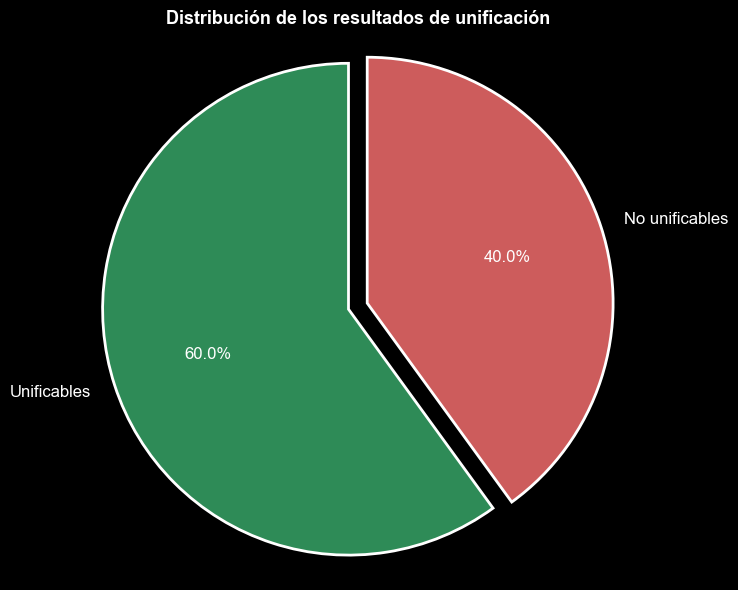

In [20]:

plt.figure(figsize=(7, 6))

plt.pie(
    cantidades,
    labels=categorias,
    colors=["seagreen", "indianred"],
    autopct="%1.1f%%",
    startangle=90,
    explode=(0.04, 0.04),
    wedgeprops={
        "edgecolor": "white",
        "linewidth": 2
    },
    textprops={"fontsize": 12}
)

plt.title(
    "Distribución de los resultados de unificación",
    fontsize=13,
    fontweight="bold"
)

plt.axis("equal")
plt.tight_layout()
plt.show()



### 5.15. Interpretación de los resultados

De los cinco ejercicios evaluados:

- Tres pares de expresiones son unificables.
- Dos pares de expresiones no son unificables.

El 60 % de los pares admite un unificador
más general, mientras que el 40 % restante
no admite una sustitución válida.

Las primeras tres pruebas permiten comprobar
que el algoritmo procesa correctamente
variables, constantes, sustituciones múltiples
y funciones anidadas.

La cuarta prueba demuestra que el algoritmo
detecta incompatibilidades entre constantes.

La quinta prueba comprueba el funcionamiento
de la verificación de ocurrencia.

Es importante señalar que el porcentaje de
expresiones unificables no representa la
precisión del algoritmo.

El algoritmo clasifica correctamente los
cinco casos, incluyendo aquellos en los que
la unificación debe fallar.

Los resultados coinciden con los puntos
de verificación establecidos en el manual.



### 5.16. Base de conocimiento del coronel West

Una base de conocimiento (KB) contiene hechos
y reglas que representan información sobre
un dominio determinado.

En el caso del coronel West, la base de
conocimiento está formada inicialmente por:

- Cuatro hechos conocidos.
- Cuatro reglas de inferencia.

Los hechos se representarán mediante un
conjunto de tuplas.

Las reglas se representarán mediante una lista,
donde cada elemento contiene:

1. Una lista de premisas.
2. Una conclusión.

Esta estructura permitirá aplicar el algoritmo
de unificación para determinar cuándo se
satisfacen las premisas de una regla y generar
nuevos hechos.


In [21]:

# Hechos iniciales de la base de conocimiento

HECHOS = {
    ("Posee", "Nono", "M1"),
    ("Misil", "M1"),
    ("Americano", "West"),
    ("Enemigo", "Nono", "America")
}

# Mostrar los hechos iniciales
print("HECHOS INICIALES")
print("=" * 40)

for i, hecho in enumerate(sorted(HECHOS), start=1):

    print(f"H{i}: {formato_termino(hecho)}")

print(f"\nTotal de hechos: {len(HECHOS)}")


HECHOS INICIALES
H1: Americano(West)
H2: Enemigo(Nono, America)
H3: Misil(M1)
H4: Posee(Nono, M1)

Total de hechos: 4



### 5.17. Representación de las reglas

Cada regla de inferencia se representará
mediante una tupla con dos elementos:

    (premisas, conclusion)

Las premisas estarán almacenadas en una lista
de expresiones.

La conclusión estará representada mediante
una tupla.

Por ejemplo, la regla:

$$Misil(x)\Rightarrow Arma(x)$$

Se representa en Python como:

    (
        [("Misil", "x")],
        ("Arma", "x")
    )

Cuando todas las premisas de una regla
se satisfacen, es posible incorporar su
conclusión a la base de conocimiento,
aplicando las sustituciones correspondientes.


In [22]:

REGLAS = [

    # R1: Venta ilegal de armas
    (
        [
            ("Americano", "x"),
            ("Arma", "y"),
            ("Vende", "x", "y", "z"),
            ("Hostil", "z")
        ],
        ("Criminal", "x")
    ),

    # R2: Venta de misiles
    (
        [
            ("Misil", "x"),
            ("Posee", "Nono", "x")
        ],
        ("Vende", "West", "x", "Nono")
    ),

    # R3: Todo misil es un arma
    (
        [
            ("Misil", "x")
        ],
        ("Arma", "x")
    ),

    # R4: Todo enemigo de América es hostil
    (
        [
            ("Enemigo", "x", "America")
        ],
        ("Hostil", "x")
    )
]

print(f"Total de reglas: {len(REGLAS)}")


Total de reglas: 4


In [23]:

def formato_regla(regla):
    """
    Convierte una regla de Python en una
    expresión de lógica de primer orden.
    """

    # Separar las premisas y la conclusión
    premisas, conclusion = regla

    # Convertir las premisas en texto
    texto_premisas = " ∧ ".join(
        formato_termino(p) for p in premisas
    )

    # Convertir la conclusión en texto
    texto_conclusion = formato_termino(conclusion)

    # Construir la representación de la regla
    return f"{texto_premisas} ⇒ {texto_conclusion}"


In [24]:

# Mostrar las reglas de la base de conocimiento

print("REGLAS DE INFERENCIA")
print("=" * 60)

for i, regla in enumerate(REGLAS, start=1):

    print(f"R{i}: {formato_regla(regla)}")
    print()


REGLAS DE INFERENCIA
R1: Americano(x) ∧ Arma(y) ∧ Vende(x, y, z) ∧ Hostil(z) ⇒ Criminal(x)

R2: Misil(x) ∧ Posee(Nono, x) ⇒ Vende(West, x, Nono)

R3: Misil(x) ⇒ Arma(x)

R4: Enemigo(x, America) ⇒ Hostil(x)



In [25]:

# Organizar las reglas en una tabla

nombres_reglas = [
    "Venta ilegal de armas",
    "Venta de misiles",
    "Clasificación de misiles",
    "Naciones hostiles"
]

datos_reglas = []

for i, (premisas, conclusion) in enumerate(REGLAS):

    datos_reglas.append({
        "Regla": f"R{i + 1}",
        "Descripción": nombres_reglas[i],
        "Premisas": " ∧ ".join(
            formato_termino(p) for p in premisas
        ),
        "Cantidad de premisas": len(premisas),
        "Conclusión": formato_termino(conclusion)
    })

df_reglas = pd.DataFrame(datos_reglas)

df_reglas


,Regla,Descripción,Premisas,Cantidad de premisas,Conclusión
0,R1,Venta ilegal de armas,"Americano(x) ∧ Arma(y) ∧ Vende(x, y, z) ∧ Host...",4,Criminal(x)
1,R2,Venta de misiles,"Misil(x) ∧ Posee(Nono, x)",2,"Vende(West, x, Nono)"
2,R3,Clasificación de misiles,Misil(x),1,Arma(x)
3,R4,Naciones hostiles,"Enemigo(x, America)",1,Hostil(x)


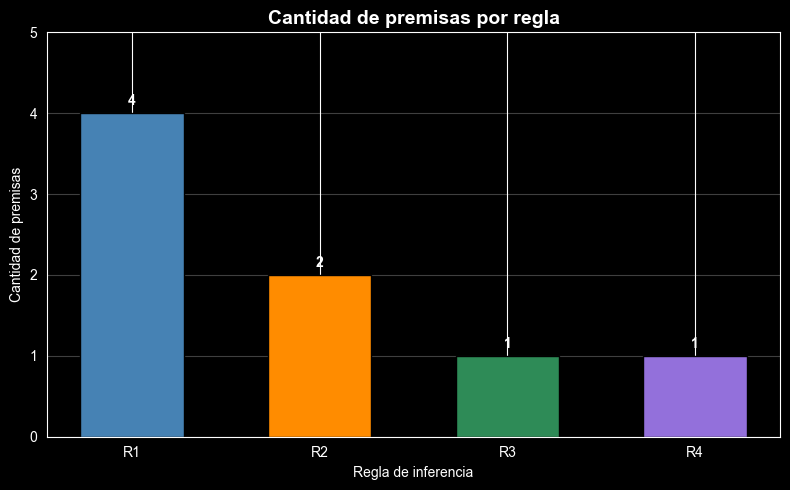

In [26]:

plt.figure(figsize=(8, 5))

barras = plt.bar(
    df_reglas["Regla"],
    df_reglas["Cantidad de premisas"],
    color=["steelblue", "darkorange", "seagreen", "mediumpurple"],
    edgecolor="black",
    width=0.55
)

plt.title(
    "Cantidad de premisas por regla",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Regla de inferencia")
plt.ylabel("Cantidad de premisas")
plt.ylim(0, 5)
plt.yticks(range(6))

for barra in barras:

    altura = barra.get_height()

    plt.text(
        barra.get_x() + barra.get_width() / 2,
        altura + 0.1,
        str(int(altura)),
        ha="center",
        fontweight="bold"
    )

plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()



### 5.18. Función renombrar()

Las variables utilizadas en distintas reglas
son independientes, aunque tengan el mismo nombre.

Por ejemplo:

$$R_2:Misil(x)\land Posee(Nono,x)\Rightarrow Vende(West,x,Nono)$$

$$R_3:Misil(x)\Rightarrow Arma(x)$$

La variable x de la regla R2 no debe
confundirse con la variable x de la regla R3.

Para evitar conflictos durante el proceso
de inferencia se realiza una estandarización
de variables.

Después del renombramiento:

$$R_2:Misil(x_2)\land Posee(Nono,x_2)\Rightarrow Vende(West,x_2,Nono)$$

$$R_3:Misil(x_3)\Rightarrow Arma(x_3)$$

El renombramiento debe aplicarse tanto a las
premisas como a la conclusión de cada regla.

Las constantes y los nombres de los predicados
deben permanecer sin modificaciones.


In [27]:

def renombrar(regla, k):
    """
    Renombra las variables de una regla.

    Parámetros:
        regla: tupla de premisas y conclusión.
        k: identificador utilizado como sufijo.

    Retorna:
        Una nueva regla con variables renombradas.
    """

    def renombrar_termino(t):

        # Caso 1: el término es una variable
        if es_var(t):
            return t + str(k)

        # Caso 2: expresión compuesta
        if isinstance(t, tuple):

            return (t[0],) + tuple(
                renombrar_termino(a)
                for a in t[1:]
            )

        # Caso 3: constante
        return t

    # Separar premisas y conclusión
    premisas, conclusion = regla

    # Renombrar las premisas
    nuevas_premisas = [
        renombrar_termino(p)
        for p in premisas
    ]

    # Renombrar la conclusión
    nueva_conclusion = renombrar_termino(conclusion)

    return nuevas_premisas, nueva_conclusion


In [28]:

# Obtener la primera regla
regla_original = REGLAS[0]

# Renombrar sus variables
regla_renombrada = renombrar(regla_original, 1)

print("REGLA ORIGINAL")
print(formato_regla(regla_original))

print("\nREGLA RENOMBRADA")
print(formato_regla(regla_renombrada))


REGLA ORIGINAL
Americano(x) ∧ Arma(y) ∧ Vende(x, y, z) ∧ Hostil(z) ⇒ Criminal(x)

REGLA RENOMBRADA
Americano(x1) ∧ Arma(y1) ∧ Vende(x1, y1, z1) ∧ Hostil(z1) ⇒ Criminal(x1)


In [29]:

print("RENOMBRAMIENTO DE VARIABLES")
print("=" * 70)

for i, regla in enumerate(REGLAS, start=1):

    nueva_regla = renombrar(regla, i)

    print(f"R{i} ORIGINAL:")
    print(formato_regla(regla))

    print(f"\nR{i} RENOMBRADA:")
    print(formato_regla(nueva_regla))

    print("-" * 70)


RENOMBRAMIENTO DE VARIABLES
R1 ORIGINAL:
Americano(x) ∧ Arma(y) ∧ Vende(x, y, z) ∧ Hostil(z) ⇒ Criminal(x)

R1 RENOMBRADA:
Americano(x1) ∧ Arma(y1) ∧ Vende(x1, y1, z1) ∧ Hostil(z1) ⇒ Criminal(x1)
----------------------------------------------------------------------
R2 ORIGINAL:
Misil(x) ∧ Posee(Nono, x) ⇒ Vende(West, x, Nono)

R2 RENOMBRADA:
Misil(x2) ∧ Posee(Nono, x2) ⇒ Vende(West, x2, Nono)
----------------------------------------------------------------------
R3 ORIGINAL:
Misil(x) ⇒ Arma(x)

R3 RENOMBRADA:
Misil(x3) ⇒ Arma(x3)
----------------------------------------------------------------------
R4 ORIGINAL:
Enemigo(x, America) ⇒ Hostil(x)

R4 RENOMBRADA:
Enemigo(x4, America) ⇒ Hostil(x4)
----------------------------------------------------------------------


In [30]:

# Regla de prueba con una función anidada

regla_anidada = (
    [
        ("Conoce", "x", ("Madre", "y"))
    ],
    ("Relacionado", "x", "y")
)

print("Regla original:")
print(formato_regla(regla_anidada))

print("\nRegla renombrada:")
print(formato_regla(
    renombrar(regla_anidada, 5)
))


Regla original:
Conoce(x, Madre(y)) ⇒ Relacionado(x, y)

Regla renombrada:
Conoce(x5, Madre(y5)) ⇒ Relacionado(x5, y5)


In [31]:

# Verificar el renombramiento de la regla R3

assert renombrar(REGLAS[2], 3) == (
    [("Misil", "x3")],
    ("Arma", "x3")
)

# Verificar que las constantes no cambien

assert renombrar(REGLAS[3], 4) == (
    [("Enemigo", "x4", "America")],
    ("Hostil", "x4")
)

# Verificar expresiones anidadas

assert renombrar(regla_anidada, 5) == (
    [("Conoce", "x5", ("Madre", "y5"))],
    ("Relacionado", "x5", "y5")
)

# Verificar que las reglas originales no se modifiquen

assert REGLAS[2] == (
    [("Misil", "x")],
    ("Arma", "x")
)

print("Todas las pruebas de renombramiento son correctas.")


Todas las pruebas de renombramiento son correctas.



### 5.19. Aplicación de una regla de inferencia

Para aplicar una regla es necesario unificar
sus premisas con los hechos conocidos.

Consideremos la regla R3:

$$Misil(x)\Rightarrow Arma(x)$$

Y el hecho:

$$Misil(M1)$$

Primero se renombra la variable de la regla:

$$Misil(x_3)\Rightarrow Arma(x_3)$$

Después se unifica la premisa con el hecho:

$$Unificar(Misil(x_3),Misil(M1))$$

Se obtiene la sustitución:

$$\theta=\{x_3\mapsto M1\}$$

Finalmente, se aplica la sustitución a la
conclusión de la regla:

$$Arma(x_3)\theta=Arma(M1)$$

El resultado es un nuevo hecho que puede
incorporarse a la base de conocimiento.


In [32]:

# Aplicar manualmente la regla R3

# Paso 1: seleccionar y renombrar la regla
premisas, conclusion = renombrar(REGLAS[2], 3)

# Paso 2: seleccionar un hecho conocido
hecho = ("Misil", "M1")

# Paso 3: unificar la premisa con el hecho
umg = unificar(premisas[0], hecho)

print("Regla seleccionada:")
print(formato_regla((premisas, conclusion)))

print("\nHecho conocido:")
print(formato_termino(hecho))

print("\nUnificador más general:")
print(formato_sustitucion(umg))

# Paso 4: generar la conclusión
if umg is not None:

    nuevo_hecho = sustituir(conclusion, umg)

    print("\nNuevo hecho derivado:")
    print(formato_termino(nuevo_hecho))

else:

    print("No fue posible aplicar la regla.")


Regla seleccionada:
Misil(x3) ⇒ Arma(x3)

Hecho conocido:
Misil(M1)

Unificador más general:
{x3 → M1}

Nuevo hecho derivado:
Arma(M1)


In [33]:

# Seleccionar y renombrar la regla R2

premisas, conclusion = renombrar(REGLAS[1], 2)

# Seleccionar los hechos correspondientes
hechos_seleccionados = [
    ("Misil", "M1"),
    ("Posee", "Nono", "M1")
]

# Inicializar las sustituciones
s = {}

print("REGLA:")
print(formato_regla((premisas, conclusion)))

# Unificar cada premisa con su hecho
for premisa, hecho in zip(
    premisas, hechos_seleccionados
):

    print("\nPremisa:", formato_termino(premisa))
    print("Hecho:", formato_termino(hecho))

    s = unificar(premisa, hecho, s)

    print("Sustituciones:", formato_sustitucion(s))

    # Si alguna premisa falla, detener el proceso
    if s is None:
        break

# Derivar la conclusión
if s is not None:

    nuevo_hecho = sustituir(conclusion, s)

    print("\nNUEVO HECHO DERIVADO:")
    print(formato_termino(nuevo_hecho))

else:

    print("\nNo fue posible aplicar la regla.")


REGLA:
Misil(x2) ∧ Posee(Nono, x2) ⇒ Vende(West, x2, Nono)

Premisa: Misil(x2)
Hecho: Misil(M1)
Sustituciones: {x2 → M1}

Premisa: Posee(Nono, x2)
Hecho: Posee(Nono, M1)
Sustituciones: {x2 → M1}

NUEVO HECHO DERIVADO:
Vende(West, M1, Nono)



### 5.20. Análisis de la aplicación de reglas

Las pruebas anteriores permiten comprobar
cómo se integran las funciones desarrolladas.

Para aplicar una regla se realizan los
siguientes pasos:

1. Seleccionar una regla.
2. Renombrar sus variables.
3. Seleccionar hechos conocidos.
4. Unificar cada premisa con su hecho.
5. Conservar las sustituciones obtenidas.
6. Aplicar las sustituciones a la conclusión.
7. Obtener un nuevo hecho.

Si alguna premisa no puede unificarse,
la regla no puede aplicarse con esa
combinación de hechos.

En las pruebas realizadas se espera obtener:

- Arma(M1), mediante la regla R3.
- Vende(West,M1,Nono), mediante la regla R2.

El siguiente paso consiste en automatizar
este procedimiento mediante la función
fol_fc_ask(), la cual realizará el
encadenamiento hacia adelante por rondas.



### 5.21. Función fol_fc_ask()

La función fol_fc_ask() implementa el
encadenamiento hacia adelante en lógica
de primer orden.

El algoritmo recibe un conjunto de hechos
iniciales y una meta que se desea demostrar.

En cada ronda realiza las siguientes operaciones:

1. Obtener los hechos conocidos.
2. Seleccionar una regla de inferencia.
3. Renombrar las variables de la regla.
4. Generar combinaciones de hechos.
5. Unificar las premisas con los hechos.
6. Aplicar las sustituciones a la conclusión.
7. Almacenar los nuevos hechos.
8. Comprobar si se ha alcanzado la meta.

Los hechos derivados durante una ronda se
incorporan al finalizar dicha ronda.

El procedimiento termina cuando:

- Se encuentra un hecho que unifica con la meta.
- No se generan nuevos hechos.

En el primer caso, la meta ha sido demostrada.

En el segundo caso, el algoritmo no encuentra
una demostración de la meta.



### 5.22. Producto cartesiano de hechos

Para comprobar las premisas de una regla
se utilizará la función product() de la
biblioteca itertools.

Esta función permite generar el producto
cartesiano de diferentes conjuntos.

Si existen n hechos y una regla tiene k
premisas, el número de combinaciones
que pueden evaluarse es:

$$C=n^k$$

Por ejemplo, con cuatro hechos iniciales:

| Regla | Premisas | Combinaciones |
|---|---:|---:|
| R1 | 4 | 256 |
| R2 | 2 | 16 |
| R3 | 1 | 4 |
| R4 | 1 | 4 |
| Total | | 280 |

No todas las combinaciones permiten aplicar
una regla.

El algoritmo debe utilizar la unificación
para identificar las combinaciones válidas.

El número de combinaciones aumenta conforme
se incorporan nuevos hechos a la base
de conocimiento.


In [34]:

# Ejemplo de producto cartesiano

elementos = ["A", "B"]

combinaciones = list(
    itertools.product(elementos, repeat=2)
)

print("Elementos:", elementos)

print("\nCombinaciones generadas:")

for combinacion in combinaciones:
    print(combinacion)

print("\nTotal:", len(combinaciones))


Elementos: ['A', 'B']

Combinaciones generadas:
('A', 'A')
('A', 'B')
('B', 'A')
('B', 'B')

Total: 4


In [35]:

# Calcular las combinaciones de hechos por regla

n = len(HECHOS)

print(f"Hechos iniciales: {n}")
print("-" * 45)

total_combinaciones = 0

for i, (premisas, conclusion) in enumerate(
    REGLAS, start=1
):

    k = len(premisas)

    cantidad = n ** k

    total_combinaciones += cantidad

    print(
        f"R{i}: {n}^{k} = "
        f"{cantidad} combinaciones"
    )

print("-" * 45)

print("Total:", total_combinaciones)


Hechos iniciales: 4
---------------------------------------------
R1: 4^4 = 256 combinaciones
R2: 4^2 = 16 combinaciones
R3: 4^1 = 4 combinaciones
R4: 4^1 = 4 combinaciones
---------------------------------------------
Total: 280


In [36]:

def fol_fc_ask(hechos, meta):
    """
    Implementa el encadenamiento hacia adelante.

    Parámetros:
        hechos: conjunto de hechos iniciales.
        meta: expresión que se desea demostrar.

    Retorna:
        True si la meta puede demostrarse.
        False si no se generan nuevos hechos
        y la meta no ha sido encontrada.
    """

    # Crear una copia de los hechos iniciales
    conocidos = set(hechos)

    # Inicializar el contador de rondas
    ronda = 0

    # Mostrar la meta
    print("META:", formato_termino(meta))

    # Comprobar si la meta ya es un hecho conocido
    for hecho in sorted(conocidos):

        if unificar(meta, hecho) is not None:

            print("La meta ya es un hecho conocido.")
            return True

    # Iniciar el proceso de inferencia
    while True:

        ronda += 1

        # Almacenar los nuevos hechos de la ronda
        nuevos = set()

        print(f"\nRONDA {ronda}")
        print("=" * 60)

        # Obtener los hechos disponibles al iniciar la ronda
        hechos_ronda = sorted(conocidos)

        # Recorrer todas las reglas
        for i, regla in enumerate(REGLAS, start=1):

            # Renombrar las variables de la regla
            premisas, conclusion = renombrar(
                regla, f"{ronda}_{i}"
            )

            # Generar las combinaciones de hechos
            combinaciones = itertools.product(
                hechos_ronda,
                repeat=len(premisas)
            )

            # Evaluar cada combinación
            for combinacion in combinaciones:

                # Inicializar las sustituciones
                s = {}

                # Unificar cada premisa con un hecho
                for premisa, hecho in zip(
                    premisas, combinacion
                ):

                    s = unificar(premisa, hecho, s)

                    # Si una premisa falla,
                    # descartar la combinación
                    if s is None:
                        break

                # Si todas las premisas se satisfacen
                if s is not None:

                    # Generar la conclusión
                    nuevo_hecho = sustituir(
                        conclusion, s
                    )

                    # Evitar hechos duplicados
                    if (
                        nuevo_hecho not in conocidos
                        and nuevo_hecho not in nuevos
                    ):

                        nuevos.add(nuevo_hecho)

                        # Mostrar la regla disparada
                        print(f"Regla R{i} disparada:")

                        print(
                            "  Sustituciones:",
                            formato_sustitucion(s)
                        )

                        print(
                            "  Nuevo hecho:",
                            formato_termino(nuevo_hecho)
                        )

        # Comprobar si se generaron nuevos hechos
        if not nuevos:

            print("No se generaron nuevos hechos.")
            print("No se pudo demostrar la meta.")

            return False

        # Incorporar los nuevos hechos
        conocidos.update(nuevos)

        print(f"\nHechos nuevos: {len(nuevos)}")
        print(f"Hechos acumulados: {len(conocidos)}")

        # Comprobar si se alcanzó la meta
        for hecho in sorted(nuevos):

            respuesta = unificar(meta, hecho)

            if respuesta is not None:

                print("\nMETA DEMOSTRADA")

                print(
                    "Hecho encontrado:",
                    formato_termino(hecho)
                )

                print(
                    "Sustituciones:",
                    formato_sustitucion(respuesta)
                )

                print(f"Rondas necesarias: {ronda}")

                return True


In [37]:

# Definir la meta

meta = ("Criminal", "West")

# Ejecutar el encadenamiento hacia adelante

resultado_west = fol_fc_ask(HECHOS, meta)

print("\n" + "=" * 60)

print("¿Criminal(West)?", resultado_west)


META: Criminal(West)

RONDA 1
Regla R2 disparada:
  Sustituciones: {x1_2 → M1}
  Nuevo hecho: Vende(West, M1, Nono)
Regla R3 disparada:
  Sustituciones: {x1_3 → M1}
  Nuevo hecho: Arma(M1)
Regla R4 disparada:
  Sustituciones: {x1_4 → Nono}
  Nuevo hecho: Hostil(Nono)

Hechos nuevos: 3
Hechos acumulados: 7

RONDA 2
Regla R1 disparada:
  Sustituciones: {x2_1 → West, y2_1 → M1, z2_1 → Nono}
  Nuevo hecho: Criminal(West)

Hechos nuevos: 1
Hechos acumulados: 8

META DEMOSTRADA
Hecho encontrado: Criminal(West)
Sustituciones: {}
Rondas necesarias: 2

¿Criminal(West)? True


In [38]:

# Consultar quién es un criminal

meta_variable = ("Criminal", "w")

resultado_variable = fol_fc_ask(
    HECHOS,
    meta_variable
)

print("\n¿Existe algún criminal?", resultado_variable)


META: Criminal(w)

RONDA 1
Regla R2 disparada:
  Sustituciones: {x1_2 → M1}
  Nuevo hecho: Vende(West, M1, Nono)
Regla R3 disparada:
  Sustituciones: {x1_3 → M1}
  Nuevo hecho: Arma(M1)
Regla R4 disparada:
  Sustituciones: {x1_4 → Nono}
  Nuevo hecho: Hostil(Nono)

Hechos nuevos: 3
Hechos acumulados: 7

RONDA 2
Regla R1 disparada:
  Sustituciones: {x2_1 → West, y2_1 → M1, z2_1 → Nono}
  Nuevo hecho: Criminal(West)

Hechos nuevos: 1
Hechos acumulados: 8

META DEMOSTRADA
Hecho encontrado: Criminal(West)
Sustituciones: {w → West}
Rondas necesarias: 2

¿Existe algún criminal? True


In [39]:

# Consultar si Nono es un criminal

meta_negativa = ("Criminal", "Nono")

resultado_nono = fol_fc_ask(
    HECHOS,
    meta_negativa
)

print("\n¿Criminal(Nono)?", resultado_nono)


META: Criminal(Nono)

RONDA 1
Regla R2 disparada:
  Sustituciones: {x1_2 → M1}
  Nuevo hecho: Vende(West, M1, Nono)
Regla R3 disparada:
  Sustituciones: {x1_3 → M1}
  Nuevo hecho: Arma(M1)
Regla R4 disparada:
  Sustituciones: {x1_4 → Nono}
  Nuevo hecho: Hostil(Nono)

Hechos nuevos: 3
Hechos acumulados: 7

RONDA 2
Regla R1 disparada:
  Sustituciones: {x2_1 → West, y2_1 → M1, z2_1 → Nono}
  Nuevo hecho: Criminal(West)

Hechos nuevos: 1
Hechos acumulados: 8

RONDA 3
No se generaron nuevos hechos.
No se pudo demostrar la meta.

¿Criminal(Nono)? False


In [40]:

# Consultar un hecho que ya existe

resultado_americano = fol_fc_ask(
    HECHOS,
    ("Americano", "West")
)

print("\n¿Americano(West)?", resultado_americano)


META: Americano(West)
La meta ya es un hecho conocido.

¿Americano(West)? True


In [41]:

# Verificar los resultados de las consultas

assert resultado_west is True

assert resultado_variable is True

assert resultado_nono is False

assert resultado_americano is True

# Verificar que la base original no se modificó

assert len(HECHOS) == 4

assert ("Criminal", "West") not in HECHOS

print("Todas las consultas son correctas.")

print(
    "La base de conocimiento original "
    "no fue modificada."
)


Todas las consultas son correctas.
La base de conocimiento original no fue modificada.



### 5.23. Análisis de eficiencia

El encadenamiento hacia adelante puede evaluar
una gran cantidad de combinaciones de hechos.

Para analizar su funcionamiento se registrarán
los siguientes indicadores:

- Número de ronda.
- Hechos disponibles al iniciar la ronda.
- Combinaciones evaluadas.
- Intentos de unificación de premisas.
- Combinaciones válidas.
- Reglas disparadas.
- Nuevos hechos derivados.
- Hechos acumulados.

Una combinación válida es aquella en la que
todas las premisas pueden unificarse con los
hechos seleccionados.

Una regla disparada se contabilizará cuando
una combinación válida produzca un hecho nuevo.

Esta distinción permite identificar el trabajo
repetido que realiza el algoritmo al evaluar
reglas cuyas conclusiones ya son conocidas.


In [42]:

def fol_fc_estadisticas(hechos, meta):
    """
    Ejecuta el encadenamiento hacia adelante
    y recopila estadísticas por ronda.

    Retorna:
        Resultado de la consulta.
        Conjunto de hechos finales.
        Lista de estadísticas.
        Lista de hechos derivados.
    """

    conocidos = set(hechos)

    estadisticas = []
    derivaciones = []

    ronda = 0

    # Comprobar los hechos iniciales
    if any(
        unificar(meta, h) is not None
        for h in conocidos
    ):

        return True, conocidos, estadisticas, derivaciones

    while True:

        ronda += 1

        nuevos = set()

        hechos_ronda = sorted(conocidos)

        combinaciones_evaluadas = 0
        intentos_unificacion = 0
        combinaciones_validas = 0
        reglas_disparadas = 0

        for i, regla in enumerate(REGLAS, start=1):

            premisas, conclusion = renombrar(
                regla, f"{ronda}_{i}"
            )

            for combinacion in itertools.product(
                hechos_ronda,
                repeat=len(premisas)
            ):

                combinaciones_evaluadas += 1

                s = {}

                for premisa, hecho in zip(
                    premisas, combinacion
                ):

                    intentos_unificacion += 1

                    s = unificar(premisa, hecho, s)

                    if s is None:
                        break

                if s is not None:

                    combinaciones_validas += 1

                    nuevo = sustituir(conclusion, s)

                    if (
                        nuevo not in conocidos
                        and nuevo not in nuevos
                    ):

                        nuevos.add(nuevo)

                        reglas_disparadas += 1

                        derivaciones.append({
                            "Ronda": ronda,
                            "Regla": f"R{i}",
                            "Hecho": formato_termino(nuevo),
                            "Sustituciones": formato_sustitucion(s)
                        })

        # Registrar las estadísticas de la ronda
        estadisticas.append({
            "Ronda": ronda,
            "Hechos iniciales": len(hechos_ronda),
            "Combinaciones": combinaciones_evaluadas,
            "Intentos de unificación": intentos_unificacion,
            "Combinaciones válidas": combinaciones_validas,
            "Reglas disparadas": reglas_disparadas,
            "Hechos nuevos": len(nuevos),
            "Hechos acumulados": len(conocidos | nuevos)
        })

        if not nuevos:

            return (
                False,
                conocidos,
                estadisticas,
                derivaciones
            )

        conocidos.update(nuevos)

        if any(
            unificar(meta, h) is not None
            for h in nuevos
        ):

            return (
                True,
                conocidos,
                estadisticas,
                derivaciones
            )


In [43]:

# Ejecutar el encadenamiento con estadísticas

(
    resultado_fc,
    hechos_finales,
    estadisticas_fc,
    derivaciones_fc
) = fol_fc_estadisticas(
    HECHOS,
    ("Criminal", "West")
)

# Crear tabla de estadísticas

df_fc = pd.DataFrame(estadisticas_fc)

df_fc


,Ronda,Hechos iniciales,Combinaciones,Intentos de unificación,Combinaciones válidas,Reglas disparadas,Hechos nuevos,Hechos acumulados
0,1,4,280,348,3,3,3,7
1,2,7,2464,2870,4,1,1,8


In [44]:

# Crear tabla con las derivaciones

df_derivaciones = pd.DataFrame(
    derivaciones_fc
)

df_derivaciones


,Ronda,Regla,Hecho,Sustituciones
0,1,R2,"Vende(West, M1, Nono)",{x1_2 → M1}
1,1,R3,Arma(M1),{x1_3 → M1}
2,1,R4,Hostil(Nono),{x1_4 → Nono}
3,2,R1,Criminal(West),"{x2_1 → West, y2_1 → M1, z2_1 → Nono}"


In [45]:

print("BASE DE CONOCIMIENTO FINAL")
print("=" * 60)

for i, hecho in enumerate(
    sorted(hechos_finales),
    start=1
):

    if hecho in HECHOS:
        tipo = "Inicial"
    else:
        tipo = "Derivado"

    print(
        f"H{i}: {formato_termino(hecho):30}"
        f" [{tipo}]"
    )

print("\nTotal de hechos:", len(hechos_finales))


BASE DE CONOCIMIENTO FINAL
H1: Americano(West)                [Inicial]
H2: Arma(M1)                       [Derivado]
H3: Criminal(West)                 [Derivado]
H4: Enemigo(Nono, America)         [Inicial]
H5: Hostil(Nono)                   [Derivado]
H6: Misil(M1)                      [Inicial]
H7: Posee(Nono, M1)                [Inicial]
H8: Vende(West, M1, Nono)          [Derivado]

Total de hechos: 8


In [46]:

print("ESTADÍSTICAS DEL ENCADENAMIENTO")
print("=" * 50)

print("Meta demostrada:", resultado_fc)

print("Rondas:", len(df_fc))

print("Hechos iniciales:", len(HECHOS))

print("Hechos finales:", len(hechos_finales))

print(
    "Hechos derivados:",
    df_fc["Hechos nuevos"].sum()
)

print(
    "Combinaciones evaluadas:",
    df_fc["Combinaciones"].sum()
)

print(
    "Intentos de unificación:",
    df_fc["Intentos de unificación"].sum()
)

print(
    "Combinaciones válidas:",
    df_fc["Combinaciones válidas"].sum()
)

print(
    "Reglas disparadas:",
    df_fc["Reglas disparadas"].sum()
)


ESTADÍSTICAS DEL ENCADENAMIENTO
Meta demostrada: True
Rondas: 2
Hechos iniciales: 4
Hechos finales: 8
Hechos derivados: 4
Combinaciones evaluadas: 2744
Intentos de unificación: 3218
Combinaciones válidas: 7
Reglas disparadas: 4



### 5.24. Visualización del encadenamiento hacia adelante

Se utilizarán gráficas para representar:

- El crecimiento de la base de conocimiento.
- Los hechos derivados por ronda.
- Las combinaciones evaluadas.
- Las combinaciones válidas.

Estas visualizaciones permitirán analizar
la evolución del proceso de inferencia
y el costo computacional asociado con
la evaluación exhaustiva de combinaciones.


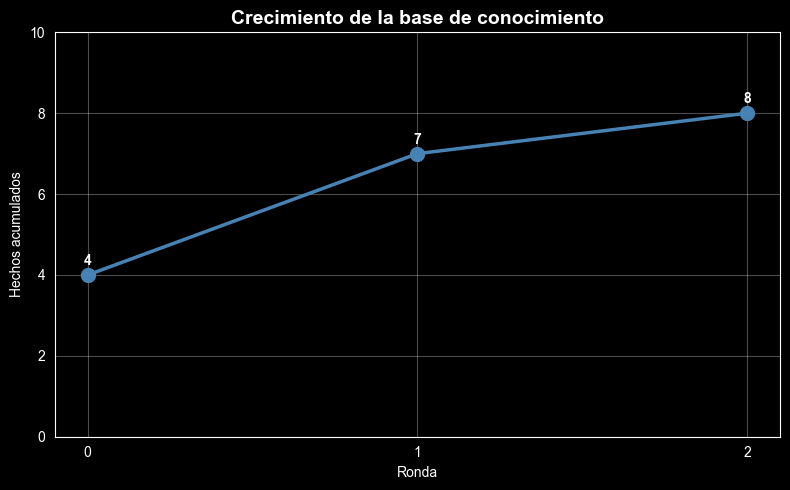

In [47]:

# Incluir la ronda inicial

rondas = [0] + df_fc["Ronda"].tolist()

acumulados = (
    [len(HECHOS)]
    + df_fc["Hechos acumulados"].tolist()
)

plt.figure(figsize=(8, 5))

plt.plot(
    rondas,
    acumulados,
    marker="o",
    markersize=10,
    linewidth=2.5,
    color="steelblue"
)

for ronda, cantidad in zip(rondas, acumulados):

    plt.text(
        ronda,
        cantidad + 0.25,
        str(cantidad),
        ha="center",
        fontweight="bold"
    )

plt.title(
    "Crecimiento de la base de conocimiento",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Ronda")
plt.ylabel("Hechos acumulados")
plt.xticks(rondas)
plt.ylim(0, max(acumulados) + 2)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


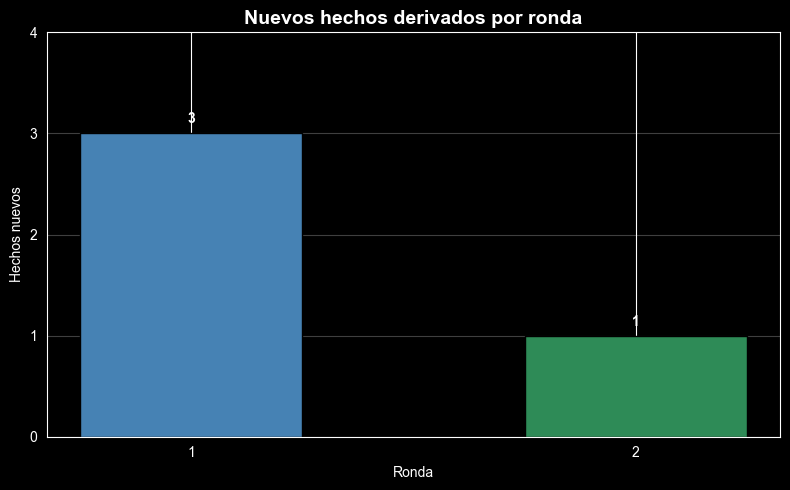

In [48]:

plt.figure(figsize=(8, 5))

barras = plt.bar(
    df_fc["Ronda"].astype(str),
    df_fc["Hechos nuevos"],
    color=["steelblue", "seagreen"],
    edgecolor="black",
    width=0.5
)

for barra in barras:

    altura = barra.get_height()

    plt.text(
        barra.get_x() + barra.get_width() / 2,
        altura + 0.1,
        str(int(altura)),
        ha="center",
        fontweight="bold"
    )

plt.title(
    "Nuevos hechos derivados por ronda",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Ronda")
plt.ylabel("Hechos nuevos")
plt.ylim(0, 4)
plt.yticks(range(5))
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()


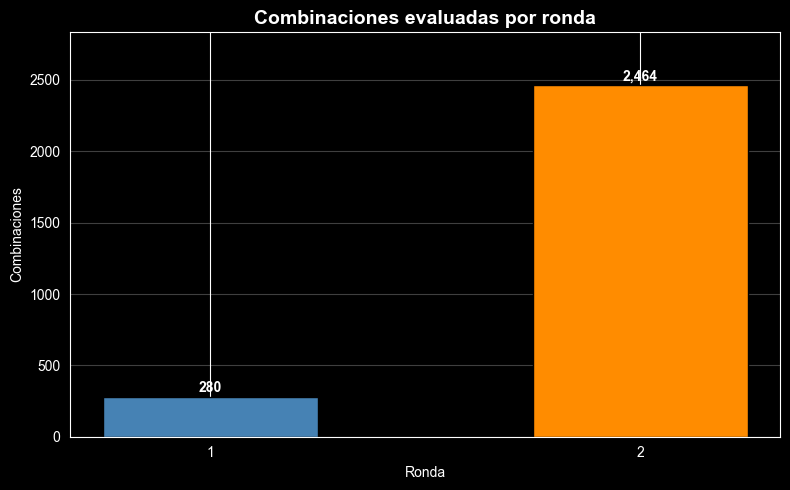

In [49]:

plt.figure(figsize=(8, 5))

barras = plt.bar(
    df_fc["Ronda"].astype(str),
    df_fc["Combinaciones"],
    color=["steelblue", "darkorange"],
    edgecolor="black",
    width=0.5
)

for barra in barras:

    altura = barra.get_height()

    plt.text(
        barra.get_x() + barra.get_width() / 2,
        altura + 30,
        f"{int(altura):,}",
        ha="center",
        fontweight="bold"
    )

plt.title(
    "Combinaciones evaluadas por ronda",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Ronda")
plt.ylabel("Combinaciones")
plt.ylim(0, max(df_fc["Combinaciones"]) * 1.15)
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()


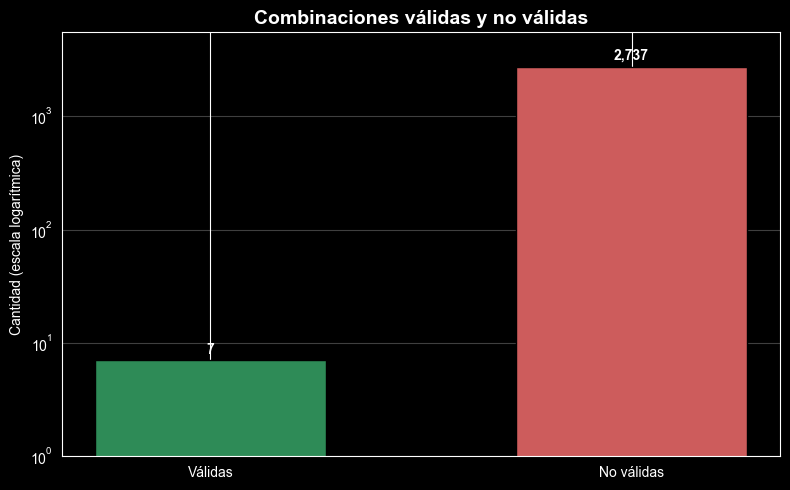

In [50]:

# Calcular cantidades totales

total_evaluadas = int(
    df_fc["Combinaciones"].sum()
)

total_validas = int(
    df_fc["Combinaciones válidas"].sum()
)

total_invalidas = total_evaluadas - total_validas

plt.figure(figsize=(8, 5))

barras = plt.bar(
    ["Válidas", "No válidas"],
    [total_validas, total_invalidas],
    color=["seagreen", "indianred"],
    edgecolor="black",
    width=0.55
)

# Utilizar escala logarítmica debido
# a la diferencia entre las cantidades

plt.yscale("log")

for barra in barras:

    altura = barra.get_height()

    plt.text(
        barra.get_x() + barra.get_width() / 2,
        altura * 1.15,
        f"{int(altura):,}",
        ha="center",
        fontweight="bold"
    )

plt.title(
    "Combinaciones válidas y no válidas",
    fontsize=14,
    fontweight="bold"
)

plt.ylabel("Cantidad (escala logarítmica)")
plt.ylim(1, total_evaluadas * 2)
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()



### 5.25. Interpretación de los resultados

El encadenamiento hacia adelante permite
demostrar que el coronel West es un criminal
a partir de cuatro hechos iniciales y cuatro
reglas de inferencia.

Durante la primera ronda se generan tres
hechos nuevos.

Durante la segunda ronda se obtiene la
conclusión Criminal(West).

La base de conocimiento aumenta de cuatro
a ocho hechos, lo que representa un incremento
del 100 %.

Sin embargo, el algoritmo realiza una
evaluación exhaustiva de combinaciones.

En la primera ronda se evalúan 280
combinaciones, mientras que en la segunda
ronda se evalúan 2464.

En total se evalúan 2744 combinaciones,
de las cuales solamente siete satisfacen
todas las premisas de una regla.

De estas siete combinaciones válidas,
cuatro generan hechos nuevos y tres
producen hechos que ya eran conocidos.

Esto demuestra que la implementación
exhaustiva del encadenamiento hacia
adelante puede realizar trabajo repetido.

Una posible optimización consiste en
seleccionar únicamente hechos cuyos
predicados coincidan con los de las
premisas antes de generar las combinaciones.

Posteriormente, se comparará esta estrategia
con el encadenamiento hacia atrás de Prolog.


In [51]:

# Verificar los resultados del encadenamiento

assert resultado_fc is True

assert len(HECHOS) == 4

assert len(hechos_finales) == 8

assert len(estadisticas_fc) == 2

assert df_fc["Hechos nuevos"].tolist() == [3, 1]

assert df_fc["Combinaciones"].tolist() == [280, 2464]

assert df_fc["Combinaciones válidas"].sum() == 7

assert ("Criminal", "West") in hechos_finales

assert ("Arma", "M1") in hechos_finales

assert ("Hostil", "Nono") in hechos_finales

assert ("Vende", "West", "M1", "Nono") in hechos_finales

print("PARTE A COMPLETADA CORRECTAMENTE")

print("La meta Criminal(West) fue demostrada.")

print("Todos los resultados fueron verificados.")


PARTE A COMPLETADA CORRECTAMENTE
La meta Criminal(West) fue demostrada.
Todos los resultados fueron verificados.


## 6. Cuestionario final

En esta sección se responden las preguntas
del manual de prácticas relacionadas con
la unificación, el encadenamiento hacia
adelante, el encadenamiento hacia atrás
y las limitaciones de Prolog.

Las respuestas se fundamentan en los
resultados experimentales obtenidos
durante las partes A, B y C.


### 6.1. ¿Qué pasaría si no renombraras las variables de cada regla?

Las variables de reglas diferentes podrían
confundirse si se utilizan sustituciones
compartidas durante el proceso de inferencia.

Aunque dos reglas utilicen una variable
con el mismo nombre, esto no significa
que representen al mismo individuo.

Por ejemplo:

- R3: Misil(x) → Arma(x).
- R4: Enemigo(x, America) → Hostil(x).

En la regla R3 se obtiene:

$$x \rightarrow M1$$

Mientras que en la regla R4 se obtiene:

$$x \rightarrow Nono$$

Si ambas variables se trataran como una
misma variable dentro de una sustitución
compartida, podría producirse un conflicto.

El renombramiento permite distinguirlas:

$$x_{3} \rightarrow M1$$

$$x_{4} \rightarrow Nono$$

Este procedimiento se conoce como
estandarización aparte.

En nuestra implementación se utilizó
la función renombrar() para garantizar
la independencia de las variables de
cada regla.

Cabe señalar que las sustituciones nuevas
e independientes también evitan conflictos
en nuestra implementación particular.



### 6.2. ¿Qué encadenamiento hace trabajo innecesario en este caso? Justifica con tu salida.

En este caso, la implementación exhaustiva
del encadenamiento hacia adelante realiza
más trabajo innecesario.

Esto ocurre porque genera todas las
combinaciones posibles de hechos para
comprobar las premisas de cada regla.

Los resultados obtenidos en Python fueron:

| Indicador | Ronda 1 | Ronda 2 | Total |
|---|---:|---:|---:|
| Combinaciones evaluadas | 280 | 2464 | 2744 |
| Intentos de unificación | 348 | 2870 | 3218 |
| Combinaciones válidas | 3 | 4 | 7 |
| Hechos nuevos | 3 | 1 | 4 |

De las 2744 combinaciones evaluadas,
solamente siete fueron válidas.

Además, tres combinaciones válidas
produjeron hechos que ya eran conocidos.

En cambio, la traza de Prolog registró:

- 9 eventos Call.
- 9 eventos Exit.
- 0 eventos Fail.
- 0 eventos Redo.

El encadenamiento hacia atrás comenzó
con la meta criminal(west) y buscó
los subobjetivos necesarios para
demostrarla.

Aunque Prolog consultó dos veces
el hecho misil(m1), evitó generar
el producto cartesiano de todos
los hechos conocidos.

Los cuatro hechos derivados por Python
fueron relevantes para demostrar la meta.
Por lo tanto, el trabajo innecesario
consistió principalmente en evaluar
combinaciones inválidas y repetir
inferencias ya realizadas.

Los eventos de Prolog y los intentos
de unificación de Python son indicadores
diferentes, por lo que no representan
una comparación directa de tiempos
de ejecución.



### 6.3. ¿Por qué Prolog no es completo aunque la resolución sí lo sea?

La resolución es un método de inferencia
completo para refutación en lógica
de primer orden.

Esto significa que, si un conjunto de
cláusulas es insatisfacible, existe
una demostración mediante resolución
que permite obtener la cláusula vacía.

Sin embargo, Prolog utiliza una estrategia
específica de resolución denominada
resolución SLD, junto con una búsqueda
en profundidad y retroceso.

Prolog selecciona los objetivos de
izquierda a derecha y explora las
cláusulas según su orden de aparición.

El problema es que puede entrar en una
rama infinita y no alcanzar otras ramas
que contienen soluciones.

Durante la Parte C se utilizó la regla:

ancestro(X,Y) :- ancestro(X,Z), progenitor(Z,Y).

Esta regla provocó una recursión infinita
porque el objetivo recursivo se ejecutaba
antes de consultar los hechos progenitor/2
y no existía un caso base.

La ejecución produjo:

- Error: Stack limit exceeded.
- Límite de pila: 0.2 GB.
- Profundidad de pila: 2,567,717.

Posteriormente, se agregó un caso base
y se modificó el orden de los objetivos:

ancestro(X,Y) :- progenitor(X,Y).

ancestro(X,Y) :- progenitor(X,Z), ancestro(Z,Y).

La consulta ancestro(A,b) devolvió
correctamente A = c y A = a.

Esto demuestra que la estrategia de
búsqueda utilizada por Prolog no garantiza
encontrar todas las soluciones existentes
en cualquier programa.

La limitación se encuentra en la estrategia
de búsqueda y no en la completitud teórica
de la resolución SLD bajo las condiciones
adecuadas.



### 6.4. Da un ejemplo de aplicación real para cada tipo de encadenamiento.

#### Encadenamiento hacia adelante

Un ejemplo es un sistema inteligente
de monitoreo de equipos industriales.

El sistema recibe continuamente datos
procedentes de sensores, como temperatura,
presión y vibración.

A partir de estos hechos aplica reglas
para identificar situaciones de riesgo.

Por ejemplo:

TemperaturaAlta(x) ∧ VibracionAlta(x)
→ RiesgoDeFalla(x)

RiesgoDeFalla(x) → GenerarAlerta(x)

El sistema comienza con los datos
disponibles y obtiene nuevas conclusiones
sin necesidad de formular una consulta
específica.

#### Encadenamiento hacia atrás

Un ejemplo es un sistema experto
de diagnóstico de fallas informáticas.

El sistema comienza con una hipótesis,
como determinar si una computadora
presenta una falla de memoria RAM.

Posteriormente, comprueba los síntomas
y las condiciones necesarias para
confirmar dicha hipótesis.

Por ejemplo:

ErroresDeMemoria(x) ∧ PruebaRAMFallida(x)
→ FallaRAM(x)

El sistema parte de la meta FallaRAM(x)
y busca evidencias que permitan
demostrarla.

Por lo tanto, el encadenamiento hacia
adelante resulta útil para monitoreo
y generación de alertas, mientras que
el encadenamiento hacia atrás resulta
útil para diagnóstico y comprobación
de hipótesis.



## 7. Resultados de la Parte B: Prolog

Se implementó el caso del coronel West
en el lenguaje Prolog mediante el
entorno SWISH.

El programa se guardó en el archivo
west.pl.

### 7.1. Resultados de las consultas

| Consulta | Resultado |
|---|---|
| criminal(Q) | Q = west |
| americano(west) | true |
| misil(m1) | true |
| arma(m1) | true |
| hostil(nono) | true |
| vende(west,m1,nono) | true |
| criminal(west) | true |
| criminal(nono) | false |
| arma(X) | X = m1 |
| hostil(X) | X = nono |
| vende(X,Y,Z) | X = west, Y = m1, Z = nono |

Los resultados coinciden con las
conclusiones obtenidas mediante
el encadenamiento hacia adelante.



### 7.2. Traza de ejecución

Se ejecutó la consulta:

trace, criminal(west).

El depurador interactivo permitió
observar los siguientes eventos:

| Paso | Evento | Objetivo |
|---:|---|---|
| 1 | Call | criminal(west) |
| 2 | Call | americano(west) |
| 3 | Exit | americano(west) |
| 4 | Call | arma(_852) |
| 5 | Call | misil(_846) |
| 6 | Exit | misil(m1) |
| 7 | Exit | arma(m1) |
| 8 | Call | vende(west,m1,_872) |
| 9 | Call | misil(m1) |
| 10 | Exit | misil(m1) |
| 11 | Call | posee(nono,m1) |
| 12 | Exit | posee(nono,m1) |
| 13 | Exit | vende(west,m1,nono) |
| 14 | Call | hostil(nono) |
| 15 | Call | enemigo(nono,america) |
| 16 | Exit | enemigo(nono,america) |
| 17 | Exit | hostil(nono) |
| 18 | Exit | criminal(west) |

Resultado final: true.

Se registraron nueve llamadas y nueve
salidas exitosas, sin eventos de fallo
ni retroceso durante esta demostración.



## 8. Resultados de la Parte C: Recursividad

### 8.1. Recursividad izquierda

La versión incorrecta del programa
produjo un error de agotamiento de pila.

| Indicador | Resultado |
|---|---|
| Error | Stack limit exceeded |
| Límite de pila | 0.2 GB |
| Pila local | 0.2 GB |
| Pila global | 19.6 MB |
| Profundidad de pila | 2567717 |
| Puntos de elección | 12 |
| Soluciones obtenidas | 0 |

### 8.2. Recursividad corregida

Se incorporó un caso base y se modificó
el orden de los objetivos recursivos.

| Consulta | Resultado |
|---|---|
| ancestro(A,b) | c, a |
| ancestro(a,X) | c, d, b, e |
| ancestro(a,b) | true |
| ancestro(d,b) | false |
| ancestro(X,Y) | 6 soluciones |

Se encontraron cuatro relaciones
directas y dos indirectas.

El programa corregido se guardó
en el archivo ancestro.pl.


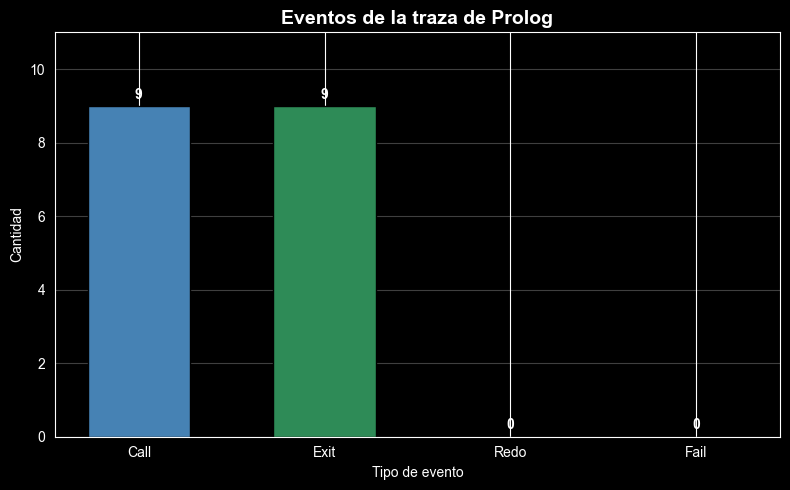

In [52]:
# Resultados reales de la traza de SWISH

eventos = ["Call", "Exit", "Redo", "Fail"]

cantidades = [9, 9, 0, 0]

plt.figure(figsize=(8, 5))

barras = plt.bar(
    eventos,
    cantidades,
    color=[
        "steelblue",
        "seagreen",
        "darkorange",
        "indianred"
    ],
    edgecolor="black",
    width=0.55
)

for barra in barras:

    altura = barra.get_height()

    plt.text(
        barra.get_x() + barra.get_width() / 2,
        altura + 0.2,
        str(int(altura)),
        ha="center",
        fontweight="bold"
    )

plt.title(
    "Eventos de la traza de Prolog",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Tipo de evento")
plt.ylabel("Cantidad")
plt.ylim(0, 11)
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

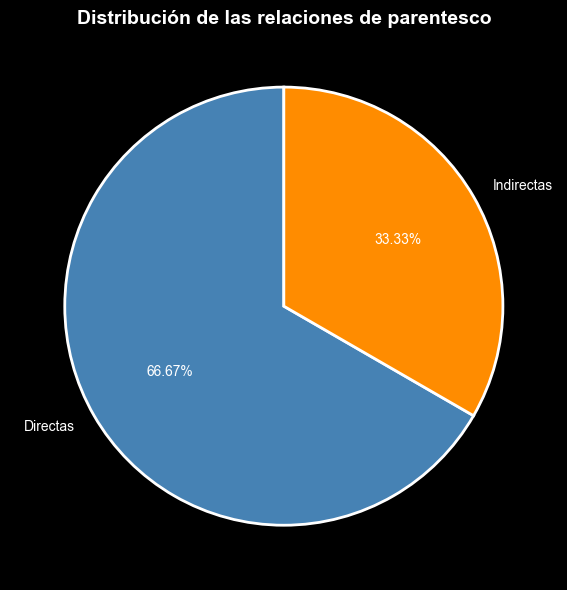

In [53]:
# Relaciones obtenidas en Prolog

tipos = ["Directas", "Indirectas"]

cantidades = [4, 2]

plt.figure(figsize=(7, 6))

plt.pie(
    cantidades,
    labels=tipos,
    autopct="%1.2f%%",
    startangle=90,
    colors=["steelblue", "darkorange"],
    wedgeprops={
        "edgecolor": "white",
        "linewidth": 2
    }
)

plt.title(
    "Distribución de las relaciones de parentesco",
    fontsize=14,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

## 9. Conclusiones

Durante esta práctica se implementaron y analizaron
diferentes mecanismos de inferencia utilizados en
la inteligencia artificial para representar el
conocimiento mediante lógica de primer orden.

La implementación del algoritmo de unificación
permitió comprender cómo se obtienen sustituciones
que hacen equivalentes dos expresiones lógicas.
Asimismo, se comprobó la importancia de la
verificación de ocurrencia y del renombramiento
de variables.

De los cinco casos de prueba de unificación,
tres fueron exitosos y dos devolvieron None,
cumpliendo con los resultados esperados.

Mediante el encadenamiento hacia adelante se
demostró que el coronel West es un criminal.
La meta se alcanzó en la segunda ronda,
obteniendo cuatro hechos nuevos a partir
de los cuatro hechos iniciales.

El análisis de eficiencia permitió identificar
que la implementación exhaustiva evaluó 2744
combinaciones y realizó 3218 intentos de
unificación, aunque solamente siete
combinaciones fueron válidas.

Posteriormente, se implementó la misma base
de conocimiento en Prolog. El encadenamiento
hacia atrás permitió demostrar la meta
criminal(west), registrando nueve eventos
Call y nueve eventos Exit, sin necesidad
de realizar retrocesos durante la demostración.

También se estudió la recursividad izquierda
mediante un ejemplo de relaciones familiares.
La versión incorrecta produjo un error de
agotamiento de pila, alcanzando una profundidad
de 2567717.

Este problema se resolvió incorporando un
caso base y modificando el orden de los
objetivos recursivos. La versión corregida
permitió obtener seis relaciones de parentesco.

Finalmente, se comprendió que la elección de
una estrategia de inferencia depende de las
características del problema. El encadenamiento
hacia adelante resulta adecuado cuando se
dispone de hechos y se desean obtener nuevas
conclusiones, mientras que el encadenamiento
hacia atrás resulta conveniente cuando se
pretende demostrar una hipótesis específica.

La práctica permitió relacionar los conceptos
de representación del conocimiento con los
algoritmos de búsqueda en profundidad y
retroceso estudiados en la Unidad 2.

### 9.1. Resumen general de resultados

| Indicador | Resultado |
|---|---|
| Pares de unificación evaluados | 5 |
| Unificaciones exitosas | 3 |
| Unificaciones fallidas | 2 |
| Reglas del caso West | 4 |
| Hechos iniciales | 4 |
| Hechos derivados | 4 |
| Hechos finales | 8 |
| Rondas de inferencia | 2 |
| Combinaciones evaluadas | 2744 |
| Intentos de unificación | 3218 |
| Combinaciones válidas | 7 |
| Meta Criminal(West) demostrada | Sí |
| Consulta criminal(Q) | Q = west |
| Eventos Call en Prolog | 9 |
| Eventos Exit en Prolog | 9 |
| Eventos Redo en Prolog | 0 |
| Eventos Fail en Prolog | 0 |
| Error de recursividad izquierda | Stack limit exceeded |
| Profundidad de pila alcanzada | 2567717 |
| Recursividad corregida | Sí |
| Relaciones de parentesco directas | 4 |
| Relaciones de parentesco indirectas | 2 |
| Total de relaciones de parentesco | 6 |

Todos los puntos de verificación establecidos
en el manual de prácticas fueron satisfechos.

## 10. Referencias bibliográficas

Campero Domínguez, J. I. (s. f.).
*Inteligencia artificial (CDC-2411):
Manual de prácticas, Unidad 3.
Representación del conocimiento y razonamiento*.
Tecnológico Nacional de México.

Russell, S. J., & Norvig, P. (2021).
*Artificial intelligence: A modern approach*
(4th ed.). Pearson.

Robinson, J. A. (1965).
A machine-oriented logic based on the
resolution principle.
*Journal of the ACM, 12*(1), 23–41.
https://doi.org/10.1145/321250.321253

Lloyd, J. W. (1987).
*Foundations of logic programming*
(2nd ed.). Springer.

Python Software Foundation. (s. f.).
*itertools — Functions creating iterators
for efficient looping*.
https://docs.python.org/3/library/itertools.html

SWI-Prolog. (s. f.).
*SWI-Prolog reference manual*.
https://www.swi-prolog.org/pldoc/

SWI-Prolog. (s. f.).
*SWISH: SWI-Prolog for sharing*.
https://swish.swi-prolog.org/

Matplotlib Development Team. (s. f.).
*Matplotlib documentation*.
https://matplotlib.org/stable/

The pandas development team. (s. f.).
*pandas documentation*.
https://pandas.pydata.org/docs/

## 11. Declaración de uso de inteligencia artificial

Durante el desarrollo de esta práctica se utilizó
ChatGPT, de OpenAI, como herramienta de apoyo
para las siguientes actividades:

- Comprensión de los fundamentos de lógica de
  primer orden.
- Explicación del algoritmo de unificación.
- Desarrollo y documentación del código en Python.
- Implementación del encadenamiento hacia adelante.
- Elaboración de estadísticas, tablas y gráficas.
- Implementación de la base de conocimiento
  en Prolog.
- Interpretación de la traza de ejecución.
- Elaboración del árbol de pruebas Y-O.
- Análisis y corrección de la recursividad izquierda.
- Resolución y explicación del cuestionario.
- Organización de las conclusiones y referencias.

Los programas fueron ejecutados y comprobados
en PyCharm y SWISH, verificando los resultados
obtenidos durante cada etapa de la práctica.

Los resultados experimentales presentados
corresponden a las ejecuciones realizadas
en dichos entornos.

---

## 12. Verificación final de la práctica

- [x] Fundamento teórico.
- [x] Preguntas previas.
- [x] Algoritmo de unificación.
- [x] Verificación de ocurrencia.
- [x] Cinco pares de prueba.
- [x] Renombramiento de variables.
- [x] Encadenamiento hacia adelante.
- [x] Demostración de Criminal(West).
- [x] Análisis de eficiencia.
- [x] Encadenamiento hacia atrás en Prolog.
- [x] Consulta criminal(Q).
- [x] Traza de ejecución.
- [x] Análisis del árbol de pruebas Y-O.
- [x] Recursividad izquierda.
- [x] Corrección de la recursividad.
- [x] Cuestionario final.
- [x] Conclusiones.
- [x] Referencias bibliográficas.
- [x] Declaración de uso de inteligencia artificial.

---

**Fin del Notebook de la Práctica 3.**

Unificación y encadenamiento en lógica de primer orden.

Inteligencia Artificial — CDC-2411

Unidad 3. Representación del conocimiento y razonamiento.

Tecnológico Nacional de México.